In [1]:
import numpy as np
import netCDF4 as nc
import xarray as xr
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.lines as mlines
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import cartopy.crs as ccrs
# from ladcp_tools import *                  # load_all_stations, ...
# from tools import *                        # setup_map, load_satellite, load_eddies, plot_eddies
from tools_eg import *

In [2]:
EXTENT = None  # e.g. [10, 20, -42, -34]
lon_min, lon_max, lat_min, lat_max = 8, 25, -41, -34
extent = [lon_min, lon_max, lat_min, lat_max]

CRUISE_START = "2026-05-14"
CRUISE_END   = "2026-07-27"

ft = 10
# ADT colours: white exactly at 0, but each side stretched separately
# (ADT here is ~ -0.3 .. +1.5 m). Lower ADT_MIN -> darker cyclone blues,
# raise ADT_MAX -> fewer saturated anticyclone reds.
ADT_MIN, ADT_MAX = -0.3, 1.5
adt_norm = TwoSlopeNorm(vmin=ADT_MIN, vcenter=0, vmax=ADT_MAX)
levels = np.arange(ADT_MIN, ADT_MAX + 0.001, 0.02)
adt_ticks = [-0.3, 0, 0.3, 0.6, 0.9, 1.2, 1.5]

crs = ccrs.PlateCarree()
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max) / 2)


BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",   # full cruise (README)
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_LADCP = BASE / "data/LADCP/traitement_avec_SADCP"
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_TRACKS = BASE / "figures/eddy_tracks"
DIR_CODE = BASE / "analysis"          # where ladcp_tools.py lives

DIR_DRIFTERS =  BASE / "data/DRIFTERS/drifters"
DIR_GEOJSON = BASE / "data/DRIFTERS/drifters_tracks.geojson"

DIR_MVP = BASE / "data/MVP_Data_processed"

# Animation
ANIM_START = "2026-07-01"                 # first drifter deployment
ANIM_END   = CRUISE_END                   # days without an ADT file are skipped
TAIL_DAYS  = 5                            # length of the track drawn behind each drifter (None = whole track)

# Drifter data: "csv" (folder of CSV snapshots, DIR_DRIFTERS) or "geojson" (DIR_GEOJSON)
DRIFTER_SOURCE = "csv"
FIRST_LAUNCH = "2026-07-01 05:00"         # fixes before this are bench tests (as in Solange's script)
FRAME_DIR = "whirls_drifters_animation"
OUT_MP4   = "whirls_drifters_animation.mp4"
FPS = 2                                   # frames (days) per second

os.makedirs(FRAME_DIR, exist_ok=True)

In [3]:
# ----------------------------------------------------------------------------
# Things loaded ONCE (they don't change from day to day)
# ----------------------------------------------------------------------------
# Bathymetry
bathymetry_data = xr.open_dataset(FNAME_BATHY)
lon_subset = bathymetry_data["lon"].sel(lon=slice(lon_min, lon_max))
lat_subset = bathymetry_data["lat"].sel(lat=slice(lat_min, lat_max))
depth_subset = bathymetry_data["topo"].sel(lon=slice(lon_min, lon_max),
                                           lat=slice(lat_min, lat_max))

# File lists
daily_ssh_files = sorted(os.listdir(DIR_SSH))
eddy_files_better = sorted(os.listdir(DIR_EDDIES['TOEDDIES_better_ADT']))
eddy_files_std = sorted(os.listdir(DIR_EDDIES['TOEDDIES']))

type_SADCP = "OS38"
sadcp = nc.Dataset(SADCP_FILES[type_SADCP])


In [4]:
transect = "Transect 12"
transect_path = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/MVP_Data_processed/{transect}/'
out_dir = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/mvp/{transect}/'
if not os.path.isdir(out_dir):
    os.mkdir(out_dir)

In [5]:
files = sorted(Path(transect_path).glob("*.csv"))
dfs = []
for k, f in enumerate(files):
    df = pd.read_csv(f)
    df["CAST"] = k          # one processed CSV file = one MVP cast
    dfs.append(df)
mvp_trans = pd.concat(dfs, ignore_index=True)
print(len(files), "files")

118 files


In [6]:
sadcp_all = {}
for inst in ["OS150", "OS38"]:
    s = cascade_add_time(xr.open_dataset(SADCP_FILES[inst]))
    s = s.sortby("time")
    s = s.isel(time=~s.indexes["time"].duplicated())
    sadcp_all[inst] = sadcp_for_transect(mvp_trans, s)

sadcp_tr  = sadcp_all["OS150"]          # used for positions (and in the cell below)
sadcp_mvp = sadcp_on_mvp_times(mvp_trans, sadcp_tr, max_gap="30min")

mvp_trans["LON (°E)"] = mvp_trans["LON (°E)"].fillna(pd.Series(sadcp_mvp["LONGITUDE"].values, index=mvp_trans.index))
mvp_trans["LAT (°N)"] = mvp_trans["LAT (°N)"].fillna(pd.Series(sadcp_mvp["LATITUDE"].values, index=mvp_trans.index))

print("MVP samples without position:", mvp_trans["LAT (°N)"].isna().sum(), "of", len(mvp_trans))

MVP samples without position: 0 of 494501


In [7]:
# OS150 above Z_SPLIT (150 m), OS38 below: sadcp_window keeps the right depths for each
a = sadcp_window("OS150", sadcp=cascade_to_window_format(sadcp_all["OS150"], pgood_min=50))
b = sadcp_window("OS38",  sadcp=cascade_to_window_format(sadcp_all["OS38"],  pgood_min=50))
print("OS150:", len(a["time"]), "profiles,", a["z"].min(), "-", a["z"].max(), "m")
print("OS38: ", len(b["time"]), "profiles,", b["z"].min(), "-", b["z"].max(), "m")

# put both on the same time axis (both are 10-min means), then stack in depth
t = np.union1d(a["time"], b["time"])
def on_t(d, key):
    out = np.full((len(t),) + d[key].shape[1:], np.nan)
    out[np.searchsorted(t, d["time"])] = d[key]
    return out

lon_a, lat_a = on_t(a, "lon"), on_t(a, "lat")
sadcp_mvp_processed = dict(
    time=t,
    lon=np.where(np.isnan(lon_a), on_t(b, "lon"), lon_a),
    lat=np.where(np.isnan(lat_a), on_t(b, "lat"), lat_a),
    z=np.concatenate([a["z"], b["z"]]),
    u=np.concatenate([on_t(a, "u"), on_t(b, "u")], axis=1),
    v=np.concatenate([on_t(a, "v"), on_t(b, "v")], axis=1))
print(len(sadcp_mvp_processed["time"]), "SADCP profiles,",
      sadcp_mvp_processed["z"].min(), "-", sadcp_mvp_processed["z"].max(), "m")

Calculating Mean
  ! PGOOD_ADCP is all 0 in this file -> PGOOD mask skipped
Calculating Mean
OS150: 146 profiles, 24.260000228881836 - 144.25999450683594 m
OS38:  146 profiles, 167.4600067138672 - 983.4600219726562 m
146 SADCP profiles, 24.260000228881836 - 983.4600219726562 m


In [8]:
# ---------------- map background for the combined figure ----------------
out_dir = str(BASE / "figures/mvp") + f"/{transect}/"

date = pd.to_datetime(mvp_trans["TIME"]).median().strftime("%Y-%m-%d")
date_compact = date.replace("-", "")
ssh = load_satellite(DIR_SSH / [f for f in daily_ssh_files if date in f or date_compact in f][0])
eddy_files, eddy_source = get_eddy_files(date_compact, date)

edds = eddies_on_transect(eddy_files, mvp_trans["LON (°E)"].values, mvp_trans["LAT (°N)"].values)
print("eddies crossed:", [("C" if e["cyc"] else "AC") + f" ({e['dist_km']:.0f} km from track)" for e in edds])


eddies crossed: ['C (15 km from track)', 'AC (58 km from track)']


118 casts used


/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/analysis/tools_eg.py:1196: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmap, shading="nearest",


  C: TOEddies center at -16 km, outside section (-2-272 km) -> not marked
  C: Nencioli minimum on the edge of the search box -> no centre


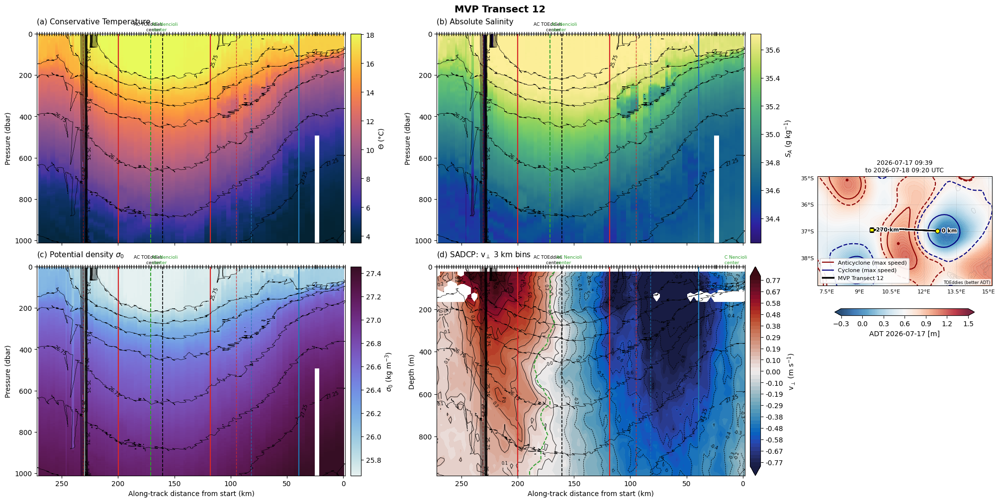

In [9]:
# ---------------- SADCP for zeta (PV) ----------------
ds = sadcp_tr                      # ADCP subset for this transect (sadcp_mvp is ~1 GB, not needed)
zdim = ds["depth"].dims[0]
u = ds["UVEL_ADCP_CORTIDE"].transpose("time", zdim).values
v = ds["VVEL_ADCP_CORTIDE"].transpose("time", zdim).values
pg = ds["PGOOD_ADCP"].transpose("time", zdim).values

u[pg < 50] = np.nan
v[pg < 50] = np.nan

args = [ssh, eddy_files, transect, eddy_source, adt_ticks, date, levels]
invert_x = True

if transect == "Transect 13" or transect == "Transect 14":
    sadcp_mvp_processed["u"] = -sadcp_mvp_processed["u"]
    sadcp_mvp_processed["v"] = -sadcp_mvp_processed["v"]
    invert_x = False
# ---------------- map + Theta / S_A / sigma0 ----------------
sec, fig, axs = process_transect(
    mvp_trans, adcp=sadcp_mvp_processed, cast_col="CAST",
    map_draw=draw_background,      # map_extent=extent  -> whole region instead of zoom
    map_args = args,
    title=f"MVP {transect}",
    eddy=edds,
    savepath=out_dir + f"{transect}_sections_hydro_adcp",
    flip_x = invert_x,
    vel_lim = 0.8)
plt.show()

In [10]:
# ---------------- CTD background profile: casts outside every TOEddies contour ----------------
# Casts selected by whirls_ctd_outside_eddies.py (outside_eddies == True in the CSV).
import warnings
DIR_CTD = BASE / "data/CTD"
MD_CTD_NC = DIR_CTD / "ctd_metadata.nc"
CLASS_CSV = DIR_CTD / "ctd_toeddies_classification.csv"
PROFILE_EXT = (".nc", ".cnv", ".csv")   # preferred profile format first
REF_DP = 1.0                            # dbar, same bins as the MVP section
REF_MIN_N = 3                           # keep only pressure levels with >= this many casts

NAMES = {"p": ["prDM", "prdM", "prSM", "pr", "PRES", "pres", "pressure", "PRESSURE"],
         "t": ["t090C", "t068C", "t190C", "TEMP", "temp", "temperature", "TEMPERATURE"],
         "s": ["sal00", "sal11", "PSAL", "psal", "salinity", "SALINITY"]}
STD_NAMES = {"p": "sea_water_pressure", "t": "sea_water_temperature",
             "s": "sea_water_practical_salinity"}


def _txt(v):
    return v.decode().strip() if isinstance(v, bytes) else str(v).strip()


def find_profile_file(name):
    """Profile file of one cast under DIR_CTD, from the metadata 'file' entry."""
    stem = Path(name).stem
    hits = [f for f in DIR_CTD.rglob(f"{stem}*") if f.suffix.lower() in PROFILE_EXT
            and f.resolve() != MD_CTD_NC.resolve()]
    if not hits:
        return None
    hits.sort(key=lambda f: (PROFILE_EXT.index(f.suffix.lower()), f.stem != stem, len(f.name)))
    return hits[0]


def _pick(cols, key, std=None):
    for n in NAMES[key]:
        if n in cols:
            return n
    low = {c.lower(): c for c in cols}
    for n in NAMES[key]:
        if n.lower() in low:
            return low[n.lower()]
    return std


def read_cnv(path):
    names, rows, bad, in_data = [], [], -9.990e-29, False
    with open(path, errors="ignore") as f:
        for line in f:
            if in_data:
                parts = line.split()
                if len(parts) == len(names):
                    rows.append(parts)
            elif line.startswith("# name"):
                names.append(line.split("=", 1)[1].split(":")[0].strip())
            elif line.startswith("# bad_flag"):
                bad = float(line.split("=")[1])
            elif line.startswith("*END*"):
                in_data = True
    df = pd.DataFrame(np.asarray(rows, float), columns=names)
    return df.mask(np.isclose(df, bad))


def read_ctd_profile(path):
    """-> p (dbar), in-situ T, practical S of one cast (downcast only)."""
    suf = path.suffix.lower()
    if suf == ".nc":
        ds = xr.open_dataset(path)
        cols = list(ds.variables)
        by_std = {k: next((v for v in cols if ds[v].attrs.get("standard_name") == s), None)
                  for k, s in STD_NAMES.items()}
        names = {k: _pick(cols, k, by_std[k]) for k in "pts"}
        if None in names.values():
            raise KeyError(f"{path.name}: no pressure/temperature/salinity among {cols}")
        p, t, s = (np.asarray(ds[names[k]].values, float).squeeze() for k in "pts")
        ds.close()
    else:
        df = read_cnv(path) if suf == ".cnv" else pd.read_csv(path)
        names = {k: _pick(list(df.columns), k) for k in "pts"}
        if None in names.values():
            raise KeyError(f"{path.name}: no pressure/temperature/salinity among {list(df.columns)}")
        p, t, s = (df[names[k]].to_numpy(float) for k in "pts")
    if p.ndim != 1:
        raise ValueError(f"{path.name}: pressure is {p.ndim}-D, expected one profile per file")
    imax = int(np.nanargmax(p))                    # downcast: surface -> deepest point
    return p[:imax + 1], t[:imax + 1], s[:imax + 1], names


def bin_on_grid(p, val, p_edges):
    idx = np.digitize(p, p_edges) - 1
    ok = (idx >= 0) & (idx < len(p_edges) - 1) & np.isfinite(val)
    s = np.bincount(idx[ok], val[ok], minlength=len(p_edges) - 1)
    n = np.bincount(idx[ok], minlength=len(p_edges) - 1)
    with np.errstate(invalid="ignore"):
        return np.where(n > 0, s / n, np.nan)


# ---- casts used for the background ----
USE_ALL_CASTS = True          # False -> only the casts outside every TOEddies contour

cls = pd.read_csv(CLASS_CSV, parse_dates=["time"])
ref_casts = (cls if USE_ALL_CASTS else cls[cls["outside_eddies"]]).reset_index(drop=True)
md = xr.open_dataset(MD_CTD_NC)
md_file = [_txt(v) for v in np.asarray(md["file"].values).ravel()]
md_pmax = np.asarray(md["max_pressure"].values, float).ravel()
md.close()
print(f"{len(ref_casts)} casts used for the background "
      f"({'all casts' if USE_ALL_CASTS else 'outside every TOEddies contour'})")

p_edges = np.arange(0, np.nanmax(md_pmax) + REF_DP, REF_DP)
p_ref = 0.5 * (p_edges[1:] + p_edges[:-1])
CT_list, SA_list, used = [], [], []
for _, c in ref_casts.iterrows():
    path = find_profile_file(md_file[c["cast"]])
    if path is None:
        print(f"  ! station {c['station']}: no profile file for '{md_file[c['cast']]}' under {DIR_CTD}")
        continue
    p, t, sp, names = read_ctd_profile(path)
    SA = gsw.SA_from_SP(sp, p, c["lon"], c["lat"])
    CT = gsw.CT_from_t(SA, t, p)
    CT_list.append(bin_on_grid(p, CT, p_edges))
    SA_list.append(bin_on_grid(p, SA, p_edges))
    used.append(c)
    print(f"  station {c['station']:>4}: {path.name} ({names['p']}, {names['t']}, {names['s']}), "
          f"0-{np.nanmax(p):.0f} dbar")

CT_all, SA_all = np.array(CT_list), np.array(SA_list)
ref_used = pd.DataFrame(used).reset_index(drop=True)
n_ref = np.isfinite(CT_all).sum(axis=0)
keep = n_ref >= REF_MIN_N
with warnings.catch_warnings():                # levels without data -> NaN, no warning
    warnings.simplefilter("ignore", RuntimeWarning)
    CT_mean, SA_mean = np.nanmean(CT_all, axis=0), np.nanmean(SA_all, axis=0)
    CT_std, SA_std = np.nanstd(CT_all, axis=0), np.nanstd(SA_all, axis=0)
ctd_ref = dict(p=p_ref[keep], CT=CT_mean[keep], SA=SA_mean[keep],
               sig0=gsw.sigma0(SA_mean, CT_mean)[keep],
               CT_std=CT_std[keep], SA_std=SA_std[keep], n=n_ref[keep])
print(f"\nbackground from {len(ref_used)} casts, 0-{ctd_ref['p'].max():.0f} dbar "
      f"(levels with >= {REF_MIN_N} casts)")
print(f"sigma0 range of the background: {ctd_ref['sig0'].min():.3f} .. {ctd_ref['sig0'].max():.3f}")
print(f"lightest MVP sigma0 in this transect: {np.nanmin(sec['sig0']):.3f}")


105 casts used for the background (all casts)
  station    1: wh26st001_tps.cnv (prDM, t090C, sal00), 0-326 dbar
  station    2: wh26st002_tps.cnv (prDM, t090C, sal00), 0-1200 dbar
  station    3: wh26st003_tps.cnv (prDM, t090C, sal00), 0-4473 dbar
  station    4: wh26st004_tps.cnv (prDM, t090C, sal00), 0-202 dbar
  station    5: wh26st005_tps.cnv (prDM, t090C, sal00), 0-1201 dbar
  station    6: wh26st006_tps.cnv (prDM, t090C, sal00), 0-251 dbar
  station    7: wh26st007_tps.cnv (prDM, t090C, sal00), 0-1205 dbar
  station    8: wh26st008_tps.cnv (prDM, t090C, sal00), 0-302 dbar
  station    9: wh26st009_tps.cnv (prDM, t090C, sal00), 0-1202 dbar
  station   10: wh26st010_tps.cnv (prDM, t090C, sal00), 0-1203 dbar
  station   11: wh26st011_tps.cnv (prDM, t090C, sal00), 0-301 dbar
  station   12: wh26st012_tps.cnv (prDM, t090C, sal00), 0-1202 dbar
  station   13: wh26st013_tps.cnv (prDM, t090C, sal00), 0-1209 dbar
  station   14: wh26st014_tps.cnv (prDM, t090C, sal00), 0-1201 dbar
  stati

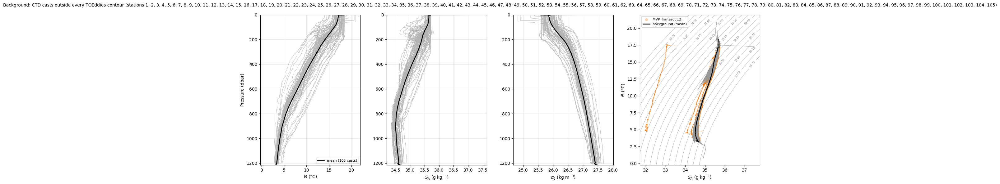

In [11]:
# ---------------- check the background profile ----------------
sig_ref_all = gsw.sigma0(SA_all, CT_all)
fig, ax = plt.subplots(1, 4, figsize=(17, 6), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.2]))
for a, data, mean, lab in [(ax[0], CT_all, ctd_ref["CT"], r"$\Theta$ (°C)"),
                           (ax[1], SA_all, ctd_ref["SA"], r"$S_A$ (g kg$^{-1}$)"),
                           (ax[2], sig_ref_all, ctd_ref["sig0"], r"$\sigma_0$ (kg m$^{-3}$)")]:
    for row in data:
        a.plot(row, p_ref, color="0.7", lw=0.6)
    a.plot(mean, ctd_ref["p"], "k", lw=2, label=f"mean ({len(ref_used)} casts)")
    a.set_xlabel(lab); a.grid(alpha=0.3)
ax[0].set_ylabel("Pressure (dbar)"); ax[0].legend(loc="lower right", fontsize=8)
for a in ax[:3]:
    a.set_ylim(ctd_ref["p"].max(), 0)

# T-S: background casts + MVP section
ax[3].scatter(sec["SA"].ravel(), sec["CT"].ravel(), s=0.3, color="tab:orange", alpha=0.3,
              label=f"MVP {transect}")
for sa_row, ct_row in zip(SA_all, CT_all):
    ax[3].plot(sa_row, ct_row, color="0.6", lw=0.6)
ax[3].plot(ctd_ref["SA"], ctd_ref["CT"], "k", lw=2, label="background (mean)")
SAg, CTg = np.meshgrid(np.linspace(*ax[3].get_xlim(), 100), np.linspace(*ax[3].get_ylim(), 100))
cs = ax[3].contour(SAg, CTg, gsw.sigma0(SAg, CTg), levels=np.arange(23.5, 28, 0.25),
                   colors="0.5", linewidths=0.4)
ax[3].clabel(cs, fmt="%.2f", fontsize=6)
ax[3].set_xlabel(r"$S_A$ (g kg$^{-1}$)"); ax[3].set_ylabel(r"$\Theta$ (°C)")
ax[3].legend(loc="upper left", fontsize=8, markerscale=10)
fig.suptitle(f"Background: CTD casts outside every TOEddies contour (stations "
             f"{', '.join(str(s) for s in ref_used['station'])})", fontsize=10)
plt.tight_layout()
plt.show()


In [12]:
# ---------------- anomaly functions (on isopycnals only) ----------------
def interp_on_rho(sigma, var, ind_rho):
    """var(sigma) -> var on the density levels ind_rho (NaN outside the sigma range).
    Sorted and de-duplicated in sigma (np.interp needs increasing x)."""
    ok = np.isfinite(sigma) & np.isfinite(var)
    if ok.sum() < 2:
        return np.full(len(ind_rho), np.nan)
    order = np.argsort(sigma[ok])
    s, idx = np.unique(sigma[ok][order], return_index=True)
    v = var[ok][order][idx]
    if s.size < 2:
        return np.full(len(ind_rho), np.nan)
    return np.interp(ind_rho, s, v, left=np.nan, right=np.nan)


def anom(ref, sec, var_name="temp", pas=0.01):
    """
    Anomalies of the MVP section relative to the background profile, ON ISOPYCNALS
    (Barabinot et al. 2025, eq. 1-2), put back at the pressure of each isopycnal in each cast:
      temp : dTheta(sigma) = Theta(sigma) - Theta*(sigma)
      sal  : dS_A(sigma)   = S_A(sigma)   - S_A*(sigma)
      disp : dp(sigma)     = p(sigma)     - p*(sigma)   isopycnal displacement (dbar),
             > 0 = isopycnal deeper than in the background (the density signal on
             isopycnals: the density anomaly itself is 0 on an isopycnal by definition)
    ref : dict(p, CT, SA, sig0) (ctd_ref).  sec : from process_transect.
    Isopycnals that do not exist in the background stay NaN (no extrapolation).
    Returns Anom with the same shape as sec["CT"] (pressure x cast).
    """
    p = sec["p"]
    sigma_grid = sec["sig0"]
    len_section = sigma_grid.shape[1]

    if var_name in ["temperature", "temp"]:
        ref_profile, var_grid = ref["CT"], sec["CT"]
    elif var_name in ["salinity", "sal"]:
        ref_profile, var_grid = ref["SA"], sec["SA"]
    elif var_name in ["disp", "displacement", "heave"]:
        ref_profile, var_grid = ref["p"], np.broadcast_to(p[:, None], sigma_grid.shape)
    else:
        raise ValueError(f"var_name must be temp, sal or disp, not {var_name!r}")

    ind_rho = np.arange(22, 28, pas)
    ref_interp = interp_on_rho(ref["sig0"], ref_profile, ind_rho)

    Anom = np.full(sigma_grid.shape, np.nan)
    for i in range(len_section):
        var_interp = interp_on_rho(sigma_grid[:, i], var_grid[:, i], ind_rho)
        Anom_rho = var_interp - ref_interp                      # anomaly on each isopycnal
        depT = interp_on_rho(sigma_grid[:, i], p, ind_rho)      # pressure of each isopycnal here

        good = np.isfinite(Anom_rho) & np.isfinite(depT)
        if good.sum() < 2:
            continue
        order = np.argsort(depT[good])
        d, idx = np.unique(depT[good][order], return_index=True)
        a = Anom_rho[good][order][idx]
        if d.size < 2:
            continue
        Anom[:, i] = np.interp(p, d, a, left=np.nan, right=np.nan)
    return Anom


In [13]:
# ---------------- figure ----------------
def plot_anomaly_section_with_map(sec, adcp, anoms, map_draw=None, map_args=None, title="",
                                  pmax=None, sig_levels=None, map_extent=None, map_pad=(2.5, 2.0),
                                  vel_lim=None, anom_lims=None, edd=None, savepath=None,
                                  flip_x=True, ref_lon=None, ref_lat=None):
    """
    Same layout as plot_section_with_map, with anomalies ON ISOPYCNALS:
                (a) Theta anomaly            (b) S_A anomaly
                (c) isopycnal displacement   (d) SADCP cross-track velocity
            small map on the right (orange = background CTD casts).
    anoms     : dict(CT=..., SA=..., disp=...) from anom(), same shape as sec["CT"].
    anom_lims : optional dict(CT=..., SA=..., disp=...) of symmetric colour limits;
                default = 99th percentile of |anomaly|.
    ref_lon, ref_lat : positions of the background casts, drawn on the map.
    Everything else is as in plot_section_with_map.
    """
    import matplotlib.patheffects as pe
    from matplotlib.gridspec import GridSpec
    try:
        import cartopy.crs as ccrs
        import cartopy.feature as cfeature
    except ImportError:
        ccrs = None

    anom_lims = anom_lims or {}
    lon, lat = sec["lon"], sec["lat"]
    xkm, p = sec["x"] / 1e3, sec["p"]
    if map_extent is None:
        map_extent = [np.nanmin(lon) - map_pad[0], np.nanmax(lon) + map_pad[0],
                      np.nanmin(lat) - map_pad[1], np.nanmax(lat) + map_pad[1]]
    sig_levels = sig_levels if sig_levels is not None else np.arange(
        np.floor(np.nanmin(sec["sig0"]) * 4) / 4, np.nanmax(sec["sig0"]), 0.25)

    fig = plt.figure(figsize=(20, 10), constrained_layout=True)
    outer = GridSpec(1, 2, figure=fig, width_ratios=[4, 1])
    gs_sec = outer[0].subgridspec(2, 2)
    gs_map = outer[1].subgridspec(2, 1, height_ratios=[1, 0.6])

    ax0 = fig.add_subplot(gs_sec[0, 0])
    axs = [ax0,
           fig.add_subplot(gs_sec[0, 1], sharex=ax0),
           fig.add_subplot(gs_sec[1, 0], sharex=ax0),
           fig.add_subplot(gs_sec[1, 1], sharex=ax0)]

    # ---- (a)-(c) anomalies on isopycnals: diverging colours, white = 0 ----
    specs = [("CT", r"$\Delta\Theta$ (°C)", r"(a) $\Theta$ anomaly on isopycnals"),
             ("SA", r"$\Delta S_A$ (g kg$^{-1}$)", r"(b) $S_A$ anomaly on isopycnals"),
             ("disp", r"$\Delta p$ (dbar)", r"(c) Isopycnal displacement ($>0$: deeper than background)")]
    for ax, (key, lab, ttl) in zip(axs[:3], specs):
        data = anoms[key]
        lim = anom_lims.get(key)
        if lim is None:
            vals = np.abs(data[np.isfinite(data)])
            lim = np.nanpercentile(vals, 99) if vals.size else 1.0
        pc = ax.pcolormesh(xkm, p, data, cmap=cmocean.cm.balance, shading="nearest",
                           vmin=-lim, vmax=lim)
        fig.colorbar(pc, ax=ax, label=lab, pad=0.01)
        ax.set_title(ttl, loc="left", fontsize=11, pad=14)

    # --- (d) SADCP cross-track velocity (unchanged) ---
    axc = axs[3]
    a_lon, a_lat, z, u, v = adcp["lon"], adcp["lat"], adcp["z"], adcp["u"], adcp["v"]
    s_m, _ = along_track_x(np.asarray(a_lon), np.asarray(a_lat),
                           sec["lon"][0], sec["lat"][0], sec["xdir"])
    s = s_m / 1e3
    ex = sec["xdir"]
    vn = -u * ex[1] + v * ex[0]        # positive = to the LEFT of the 0 km -> end direction

    edges = np.arange(np.floor(np.nanmin(s)), np.ceil(np.nanmax(s)) + DS_KM, DS_KM)
    xg, V, _ = bin_columns(s, vn, edges)
    V = fill_z_gaps(V, z)

    if vel_lim is None:
        vals = np.abs(V.ravel())
        vlim = max(0.1, np.round(np.nanpercentile(vals[np.isfinite(vals)], 98) * 10) / 10)
    else:
        vlim = vel_lim
    fill_lev = np.linspace(-vlim, vlim, N_FILL + 1)
    cf = axc.contourf(xg, z, V.T, levels=fill_lev, cmap=cmocean.cm.balance, extend="both")
    nstep = int(np.ceil(vlim / C_LINE_STEP)) + 1
    line_lev = np.round(np.arange(-nstep, nstep + 1) * C_LINE_STEP, 3)
    cs = axc.contour(xg, z, V.T, levels=line_lev, colors="k", linewidths=0.6)
    axc.clabel(cs, cs.levels, fmt="%.1f", fontsize=6, inline=True, inline_spacing=2)
    cbc = fig.colorbar(cf, ax=axc, pad=0.01)
    cbc.set_ticks(fill_lev[1::3])
    cbc.ax.set_yticklabels([f"{0.0 if abs(t) < 1e-9 else t:.2f}" for t in fill_lev[1::3]])
    cbc.set_label(r"v$_\perp$ (m s$^{-1}$)")
    axc.set_title(fr"(d) SADCP: v$_\perp$ {DS_KM:.0f} km bins", loc="left", fontsize=11, pad=14)

    edds = [edd] if isinstance(edd, dict) else list(edd or [])
    if edds:
        mark_eddies_on_sections(axs, sec, z, a_lon, a_lat, u, v, edds)

    for ax in axs:
        cs = ax.contour(xkm, p, sec["sig0"], levels=sig_levels, colors="k", linewidths=0.5)
        ax.clabel(cs, cs.levels[::2], fontsize=7, fmt="%.2f")
        ax.plot(xkm, np.zeros_like(xkm), "|", color="k", ms=6, clip_on=False)

    p_bot = pmax if pmax else np.nanmax(p)
    z_bot = pmax if pmax else np.nanmax(z)
    for ax in axs[:3]:
        ax.set_ylim(p_bot, 0)
        ax.set_ylabel("Pressure (dbar)")
    axc.set_ylim(z_bot, 0)
    axc.set_ylabel("Depth (m)")

    axs[0].set_xlim(np.nanmin(xkm), np.nanmax(xkm))
    if flip_x:
        axs[0].invert_xaxis()
    for ax in axs[:2]:
        ax.tick_params(labelbottom=False)
    for ax in axs[2:]:
        ax.tick_params(labelbottom=True)
        ax.set_xlabel("Along-track distance from start (km)")

    # ======================= map (small, right) =======================
    if ccrs is not None:
        crs = ccrs.PlateCarree()
        proj = ccrs.Mercator(central_longitude=np.mean(map_extent[:2]))
        axm = fig.add_subplot(gs_map[0], projection=proj)
        axm.set_extent(map_extent, crs=crs)
        tr = dict(transform=crs)
    else:
        crs, tr = None, {}
        axm = fig.add_subplot(gs_map[0])
        axm.set_xlim(map_extent[:2]); axm.set_ylim(map_extent[2:])
        axm.set_aspect(1 / np.cos(np.deg2rad(np.mean(map_extent[2:]))))

    if map_draw is not None:
        map_draw(axm, crs, *(map_args or []))

    if ccrs is not None:
        axm.add_feature(cfeature.LAND, facecolor="0.8", zorder=50)
        axm.coastlines(resolution="50m", linewidth=0.6, zorder=51)
        gl = axm.gridlines(crs=crs, draw_labels=True, linewidth=0.4, color="0.5",
                           alpha=0.4, linestyle="--")
        gl.top_labels = gl.right_labels = False
        gl.xlabel_style = gl.ylabel_style = {"size": 8}
    else:
        axm.grid(lw=0.4, alpha=0.4, ls="--")
        axm.tick_params(labelsize=8)

    halo = [pe.Stroke(linewidth=4.5, foreground="white"), pe.Normal()]
    axm.plot(lon, lat, "-", color="k", lw=2, path_effects=halo, zorder=100, **tr)
    if ref_lon is not None and len(ref_lon):
        axm.scatter(ref_lon, ref_lat, s=25, color="orange", edgecolor="k", linewidth=0.5,
                    zorder=101, **tr)
    for i, lab in [(0, "0 km"), (-1, f"{xkm[-1]:.0f} km")]:
        axm.plot(lon[i], lat[i], marker="o" if i == 0 else "s", ms=6, mfc="yellow",
                 mec="k", mew=1, zorder=102, **tr)
        axm.annotate(lab, (lon[i], lat[i]), xytext=(6, 0), textcoords="offset points",
                     fontsize=8, fontweight="bold", va="center", zorder=103,
                     path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
                     xycoords=crs._as_mpl_transform(axm) if crs is not None else "data")
    t0 = sec["time"][0].strftime("%Y-%m-%d %H:%M")
    t1 = sec["time"][-1].strftime("%Y-%m-%d %H:%M")
    axm.set_title(f"{t0}\nto {t1} UTC", fontsize=9)

    fig.suptitle(title, fontsize=14, fontweight="bold")
    if savepath:
        fig.savefig(savepath, dpi=300, bbox_inches="tight")
    return fig, [axm] + axs


CT    anomaly: -12.025 .. +1.565, 93% of the section filled
SA    anomaly: -2.810 .. +0.247, 93% of the section filled
disp  anomaly: -401.258 .. +924.405, 93% of the section filled
  C: TOEddies center at -16 km, outside section (-2-272 km) -> not marked
  C: Nencioli minimum on the edge of the search box -> no centre


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_64588/3309952731.py:55: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmocean.cm.balance, shading="nearest",


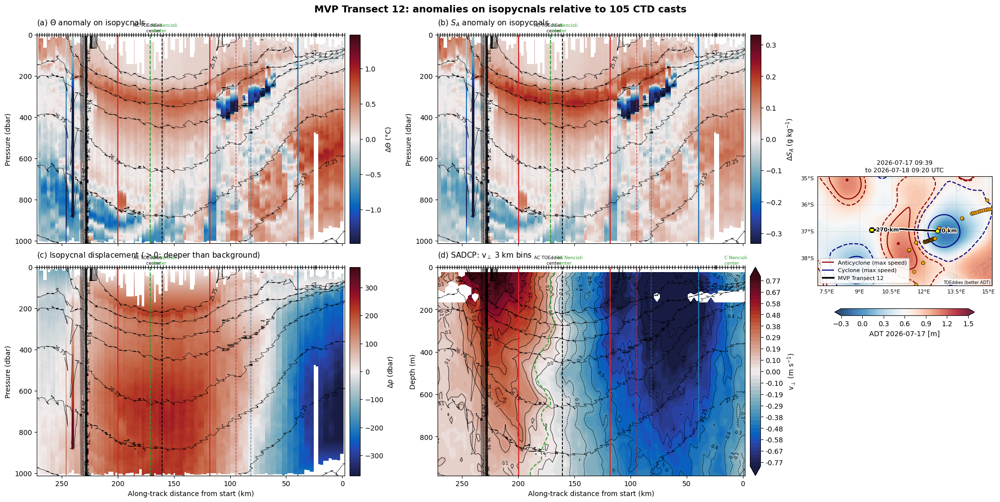

In [14]:
# ---------------- run ----------------
anoms = dict(CT=anom(ctd_ref, sec, "temp"),
             SA=anom(ctd_ref, sec, "sal"),
             disp=anom(ctd_ref, sec, "disp"))
for k, a in anoms.items():
    print(f"{k:5s} anomaly: {np.nanmin(a):+.3f} .. {np.nanmax(a):+.3f}, "
          f"{np.isfinite(a).mean() * 100:.0f}% of the section filled")

fig, axs = plot_anomaly_section_with_map(
    sec, sadcp_mvp_processed, anoms,
    map_draw=draw_background, map_args=args,
    title=f"MVP {transect}: anomalies on isopycnals relative to {len(ref_used)} CTD casts",
    edd=edds, flip_x=invert_x, vel_lim=0.8,
    ref_lon=ref_used["lon"].values, ref_lat=ref_used["lat"].values,
    savepath=out_dir + f"{transect}_section_anomalies_ctdref_adcp")
plt.show()


## Transect 12 vs Transect 13
Both transects with the same steps as above, the same CTD background (`ctd_ref`) and the same colour bars; 
then the maximum anomalies inside the anticyclone (TOEddies outer contour) and their change per day.

In [15]:
# ---------------- Transects 12 and 13: same steps as the cells above, for both ----------------
from matplotlib.path import Path as MplPath

# TRANSECTS = ["Transect 12", "Transect 13"]
TRANSECTS = [transect]

# SADCP files: loaded once
sadcp_full = {}
for inst in ["OS150", "OS38"]:
    s = cascade_add_time(xr.open_dataset(SADCP_FILES[inst])).sortby("time")
    sadcp_full[inst] = s.isel(time=~s.indexes["time"].duplicated())


def merged_sadcp(sadcp_tr_all):
    """OS150 above Z_SPLIT + OS38 below, on the same 10-min time axis (as in the SADCP cell)."""
    a = sadcp_window("OS150", sadcp=cascade_to_window_format(sadcp_tr_all["OS150"], pgood_min=50))
    b = sadcp_window("OS38", sadcp=cascade_to_window_format(sadcp_tr_all["OS38"], pgood_min=50))
    t = np.union1d(a["time"], b["time"])

    def on_t(d, key):
        out = np.full((len(t),) + d[key].shape[1:], np.nan)
        out[np.searchsorted(t, d["time"])] = d[key]
        return out

    lon_a, lat_a = on_t(a, "lon"), on_t(a, "lat")
    return dict(time=t,
                lon=np.where(np.isnan(lon_a), on_t(b, "lon"), lon_a),
                lat=np.where(np.isnan(lat_a), on_t(b, "lat"), lat_a),
                z=np.concatenate([a["z"], b["z"]]),
                u=np.concatenate([on_t(a, "u"), on_t(b, "u")], axis=1),
                v=np.concatenate([on_t(a, "v"), on_t(b, "v")], axis=1))


def prepare_transect(transect):
    """MVP section, SADCP, eddies, map background and anomalies of one transect."""
    files = sorted((DIR_MVP / transect).glob("*.csv"))
    dfs = []
    for k, f in enumerate(files):
        df = pd.read_csv(f)
        df["CAST"] = k                       # one processed CSV file = one MVP cast
        dfs.append(df)
    mvp = pd.concat(dfs, ignore_index=True)

    sadcp_tr_all = {inst: sadcp_for_transect(mvp, s) for inst, s in sadcp_full.items()}
    nav = sadcp_on_mvp_times(mvp, sadcp_tr_all["OS150"], max_gap="30min",
                             keep=("LATITUDE", "LONGITUDE"))
    mvp["LON (°E)"] = mvp["LON (°E)"].fillna(pd.Series(nav["LONGITUDE"].values, index=mvp.index))
    mvp["LAT (°N)"] = mvp["LAT (°N)"].fillna(pd.Series(nav["LATITUDE"].values, index=mvp.index))
    adcp = merged_sadcp(sadcp_tr_all)

    date = pd.to_datetime(mvp["TIME"]).median().strftime("%Y-%m-%d")
    date_compact = date.replace("-", "")
    ssh = load_satellite(DIR_SSH / [f for f in daily_ssh_files if date in f or date_compact in f][0])
    eddy_files, eddy_source = get_eddy_files(date_compact, date)
    edds = eddies_on_transect(eddy_files, mvp["LON (°E)"].values, mvp["LAT (°N)"].values)

    # section: the same steps as process_transect, without its figure
    casts = fill_cast_positions(split_by_cast_id(mvp, "CAST"))
    sec = build_section(casts, dp=1.0)
    sec["x"], sec["xdir"] = along_track_x(sec["lon"], sec["lat"])

    invert_x = transect != "Transect 13"     # same convention as the SADCP cell above
    if invert_x:                         # sign flip on a copy, so re-running is safe
        adcp = dict(adcp, u=-adcp["u"], v=-adcp["v"])
        flip_x = True
    else:
        flip_x = False

    anoms = dict(CT=anom(ctd_ref, sec, "temp"),
                 SA=anom(ctd_ref, sec, "sal"),
                 disp=anom(ctd_ref, sec, "disp"))
    eddy_txt = [("C" if e["cyc"] else "AC") + f" ({e['dist_km']:.0f} km)" for e in edds]
    print(f"{transect}: {len(files)} casts, {date}, eddies crossed: {eddy_txt}")
    return dict(transect=transect, sec=sec, adcp=adcp, anoms=anoms, edds=edds, date=date,
                invert_x=invert_x, flip_x=flip_x,
                args=[ssh, eddy_files, transect, eddy_source, adt_ticks, date, levels])


runs = [prepare_transect(tr) for tr in TRANSECTS]

Calculating Mean
  ! PGOOD_ADCP is all 0 in this file -> PGOOD mask skipped
Calculating Mean
Transect 12: 118 casts, 2026-07-17, eddies crossed: ['C (15 km)', 'AC (58 km)']


common colour limits: {'CT': 1.475, 'SA': 0.332, 'disp': 372.41} | v: 0.8 m/s
  C: TOEddies center at -16 km, outside section (-2-272 km) -> not marked
  C: Nencioli minimum on the edge of the search box -> no centre


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_64588/3309952731.py:55: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmocean.cm.balance, shading="nearest",


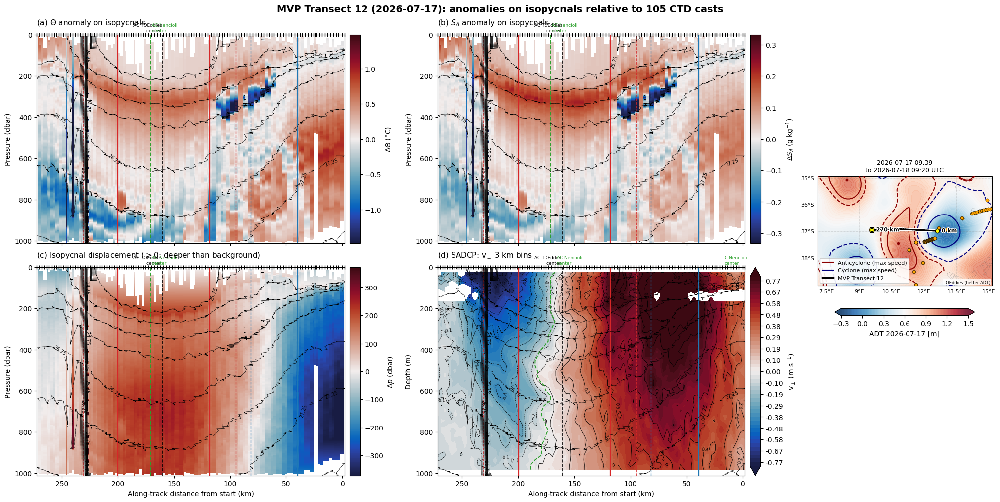

In [16]:
# ---------------- same colour bars on both figures ----------------
def common_limits(runs, pct=99):
    """Symmetric colour limit per anomaly: pct-th percentile of |anomaly| over ALL transects."""
    lims = {}
    for key in ["CT", "SA", "disp"]:
        vals = np.concatenate([np.abs(r["anoms"][key][np.isfinite(r["anoms"][key])]) for r in runs])
        lims[key] = float(np.percentile(vals, pct))
    return lims


anom_lims = common_limits(runs)
sig_all = np.concatenate([r["sec"]["sig0"][np.isfinite(r["sec"]["sig0"])] for r in runs])
sig_levels = np.arange(np.floor(sig_all.min() * 4) / 4, sig_all.max(), 0.25)
pmax = max(np.nanmax(r["sec"]["p"]) for r in runs)
print("common colour limits:", {k: round(v, 3) for k, v in anom_lims.items()}, "| v: 0.8 m/s")

for r in runs:
    out = str(BASE / "figures/mvp" / r["transect"]) + "/"
    os.makedirs(out, exist_ok=True)
    fig, axs = plot_anomaly_section_with_map(
        r["sec"], r["adcp"], r["anoms"],
        map_draw=draw_background, map_args=r["args"],
        title=f"MVP {r['transect']} ({r['date']}): anomalies on isopycnals relative to "
              f"{len(ref_used)} CTD casts",
        edd=r["edds"], flip_x=r["flip_x"], vel_lim=0.8, anom_lims=anom_lims,
        sig_levels=sig_levels, pmax=pmax,
        ref_lon=ref_used["lon"].values, ref_lat=ref_used["lat"].values,
        savepath=out + f"{r['transect']}_section_anomalies_ctdref_adcp_common")
    plt.show()


In [17]:
# ---------------- maximum anomalies in the anticyclone, and change per day ----------------
from matplotlib.path import Path as MplPath

LABELS = {"CT": ("ΔΘ", "°C"), "SA": ("ΔS_A", "g/kg"), "disp": ("Δp", "dbar")}


def anticyclone_casts(r):
    """Casts inside the TOEddies OUTER contour of the anticyclone(s) crossed by the transect."""
    pts = np.c_[r["sec"]["lon"], r["sec"]["lat"]]
    inside = np.zeros(len(pts), bool)
    for e in r["edds"]:
        if not e["cyc"]:
            inside |= MplPath(e["outer"]).contains_points(pts)
    return inside


def eddy_stats(r):
    sec, inside = r["sec"], anticyclone_casts(r)
    if not inside.any():
        print(f"  ! {r['transect']}: no cast inside an anticyclone contour -> whole section used")
        inside[:] = True
    t_mid = pd.DatetimeIndex(sec["time"])[inside].mean()
    rows = []
    for key, (name, unit) in LABELS.items():
        a = np.where(inside[None, :], r["anoms"][key], np.nan)
        if not np.isfinite(a).any():
            continue
        ip, ic = np.unravel_index(np.nanargmax(a), a.shape)
        rows.append(dict(transect=r["transect"], time=t_mid, var=name, unit=unit,
                         max=a[ip, ic], p99=np.nanpercentile(a, 99), min=np.nanmin(a),
                         p_at_max=sec["p"][ip], x_at_max_km=sec["x"][ic] / 1e3,
                         sig0_at_max=sec["sig0"][ip, ic], n_casts=int(inside.sum())))
    return rows


stats = pd.DataFrame([row for r in runs for row in eddy_stats(r)])
pd.set_option("display.float_format", "{:.3f}".format)
print(stats.drop(columns="time").to_string(index=False))

# change between the two transects (only when two transects are run)
if len(TRANSECTS) >= 2:
    a, b = TRANSECTS[0], TRANSECTS[1]
    dt_days = (stats.loc[stats.transect == b, "time"].iloc[0]
               - stats.loc[stats.transect == a, "time"].iloc[0]).total_seconds() / 86400
    print(f"\n{a} -> {b}: {dt_days:.2f} days between the anticyclone crossings\n")
    chg = []
    for name, unit in LABELS.values():
        sa = stats[(stats.transect == a) & (stats["var"] == name)]
        sb = stats[(stats.transect == b) & (stats["var"] == name)]
        if sa.empty or sb.empty:
            continue
        for col in ["max", "p99", "sig0_at_max", "p_at_max"]:
            d = sb[col].iloc[0] - sa[col].iloc[0]
            u = {"max": unit, "p99": unit, "sig0_at_max": "kg/m3", "p_at_max": "dbar"}[col]
            chg.append(dict(var=name, quantity=col, **{a: sa[col].iloc[0], b: sb[col].iloc[0]},
                            change=d, per_day=d / dt_days, unit=u))
    changes = pd.DataFrame(chg)
    print(changes.to_string(index=False))


   transect  var unit     max     p99      min  p_at_max  x_at_max_km  sig0_at_max  n_casts
Transect 12   ΔΘ   °C   1.565   0.696  -12.025  1003.500      229.240       27.461       58
Transect 12 ΔS_A g/kg   0.247   0.202   -2.810   308.500      186.002       26.210       58
Transect 12   Δp dbar 924.405 250.663 -210.939   944.500      229.240       27.175       58


## Water masses on the MVP sections, classified in S_A–Θ space
Definitions from `writing/Agulhas_Retroflection_water_masses_WHIRLS_FINAL_origins.docx` (24 boxes: surface, central, mode, intermediate, deep).

* **Everything is tested in S_A–Θ (TEOS-10)**, on the MVP grid (S_A, Θ from `build_section`):
  * θ limits (Emery and Meincke 1986, You 1997, Olson et al. 1992, Tsubouchi et al. 2010, Karstensen and Tomczak 1997) become the curves Θ = `gsw.CT_from_pt(S_A, θ)`, evaluated at the S_A of each sample (exact, not an approximation);
  * S_P limits become S_A limits with `gsw.SR_from_SP` (reference salinity, i.e. the "SR" values in the doc; the boxes are climatological, so no δS_A);
  * σ₀ (= σθ in TEOS-10) and σ₁ are computed from (S_A, Θ), so density limits are exact curves on the S_A–Θ diagram;
  * Θ, S_A limits of Barabinot et al. (2025) are used as published.
* A sample belongs to a box if it satisfies every limit (limits inclusive).
* **Depth check:** a box only counts inside the pressure range of its group: surface 0–250 dbar, central 100–800 dbar, mode 0–800 dbar, intermediate 250–2000 dbar, deep ≥ 1500 dbar (`DEPTH_RANGES`). SACW and ESACW are exempt (`DEPTH_EXEMPT`), because the Agulhas region is where they form, so they are not yet tied to a depth. Samples in an S_A–Θ box but outside its depth range are removed from that box (listed in the printout only); the per-box panels show each box only within its depth range, and a box with no sample inside its range is not drawn.
* **Boxes overlap and no box has priority**: every match is kept and the overlaps are printed. Figures per transect: (1) one panel per box, plus the number of boxes per sample; (2) one section coloured by the *combination* of boxes; (3) the S_A–Θ diagram with the box outlines. In practice almost every sample is in several boxes, because the Emery and Meincke (1986) boxes are broad (SASW alone spans θ 3.2–15 °C, S 34.0–35.5).
* Oxygen is not used. The pending Zhou et al. (2024) spicity classes are not included (no numerical boundaries).
* Needs `sadcp_full` (cell "Transects 12 and 13"), `eddy_files_better` / `eddy_files_std` and `runs`, `anticyclone_casts` from the cells above.

In [18]:
# ---------------- water-mass boxes (FINAL doc), every limit tested in S_A - Theta ----------------
import re
import textwrap
import warnings
from collections import Counter
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.lines as mlines
# Boxes, depth ranges and the classification live in water_masses.py (shared with
# eddy_characteristics.ipynb): edit them there.
from water_masses import (WM_BOXES, WM_BY_ID, WM_IDS, DEPTH_RANGES, DEPTH_EXEMPT, box_mask,
                          depth_mask, depth_text, box_text, classify, combo_ids, combo_name)

print(f"{len(WM_BOXES)} boxes, in their S_A-Θ form:")
for b in WM_BOXES:
    print(f"  {b['id']:10s} [{b['group']:12s}] {box_text(b):55s} {depth_text(b):18s} "
          f"(published: {b['pub']}; {b['cite']})")

20 boxes, in their S_A-Θ form:
  SMW        [surface     ] σ0 ≤ 25.6                                               p 0–250 dbar       (published: σ0 < 25.6; Barabinot et al. (2025))
  AASW       [surface     ] Θ≈-1.00–1.00 °C, S_A 34.16–34.76                        p 0–250 dbar       (published: θ −1.0–1.0, S 34.0–34.6; Emery and Meincke (1986))
  BBW        [surface     ] Θ≈25.13–29.16 °C, S_A 28.13–35.17                       p 0–250 dbar       (published: θ 25–29, S 28.0–35.0; Emery and Meincke (1986))
  ASW        [surface     ] Θ≈23.96–29.96 °C, S_A 35.67–36.97                       p 0–250 dbar       (published: θ 24–30, S 35.5–36.8; Emery and Meincke (1986))
  IEW        [surface     ] Θ≈7.99–23.00 °C, S_A 34.76–35.17                        p 0–250 dbar       (published: θ 8–23, S 34.6–35.0; Emery and Meincke (1986))
  SICW_EM86  [central     ] Θ≈7.99–24.99 °C, S_A 34.76–35.97                        p 100–800 dbar     (published: θ 8–25, S 34.6–35.8; Emery and Meincke (1986))
  

In [19]:
# ---------------- classify every MVP transect; print the samples that are in several water masses ----------------
WM_TRANSECTS = "all"        # "all" (every 'transect N' folder in DIR_MVP) or a list, e.g. ["Transect 12", "Transect 13"]


def list_mvp_transects():
    found = []
    for d in DIR_MVP.iterdir():
        m = re.fullmatch(r"(?i)transect (\d+)", d.name)
        if m and d.is_dir() and any(d.glob("*.csv")):
            found.append(int(m.group(1)))
    return [f"Transect {n}" for n in sorted(found)]


def prepare_wm_transect(transect):
    """MVP section (S_A, Theta on the 1-dbar grid), positions and TOEddies contours of one transect:
    the steps of prepare_transect, without the SADCP section and the anomalies."""
    files = sorted((DIR_MVP / transect).glob("*.csv"))
    mvp = pd.concat([pd.read_csv(f).assign(CAST=k) for k, f in enumerate(files)], ignore_index=True)
    nav = sadcp_on_mvp_times(mvp, sadcp_for_transect(mvp, sadcp_full["OS150"]), max_gap="30min",
                             keep=("LATITUDE", "LONGITUDE"))
    mvp["LON (°E)"] = mvp["LON (°E)"].fillna(pd.Series(nav["LONGITUDE"].values, index=mvp.index))
    mvp["LAT (°N)"] = mvp["LAT (°N)"].fillna(pd.Series(nav["LATITUDE"].values, index=mvp.index))
    date = pd.to_datetime(mvp["TIME"]).median().strftime("%Y-%m-%d")
    eddy_files, _ = get_eddy_files(date.replace("-", ""), date)
    edds = eddies_on_transect(eddy_files, mvp["LON (°E)"].values, mvp["LAT (°N)"].values)
    casts = fill_cast_positions(split_by_cast_id(mvp, "CAST"))
    sec = build_section(casts, dp=1.0)
    sec["x"], sec["xdir"] = along_track_x(sec["lon"], sec["lat"])
    return dict(transect=transect, sec=sec, edds=edds, date=date)


def orientation(sec):
    """(flip_x, label): put West (or South, for a meridional section) on the left of the plot."""
    lon, lat = sec["lon"], sec["lat"]
    dx = (lon[-1] - lon[0]) * np.cos(np.deg2rad(np.nanmean(lat)))
    dy = lat[-1] - lat[0]
    if abs(dx) >= abs(dy):
        return dx < 0, "W ←    → E"
    return dy < 0, "S ←    → N"


names = list_mvp_transects() if WM_TRANSECTS == "all" else list(WM_TRANSECTS)
done = {r["transect"]: r for r in runs}            # transects already prepared above are reused
wm_runs = []
for tr in names:
    try:
        r = done.get(tr) or prepare_wm_transect(tr)
    except Exception as err:                       # e.g. no SADCP navigation for that day
        print(f"  ! {tr}: skipped ({type(err).__name__}: {err})")
        continue
    r["wm_masks"], r["wm_removed"], r["wm_code"], r["valid"] = classify(r["sec"])
    r["n_match"] = sum(m.astype(int) for m in r["wm_masks"].values())
    r["wm_flip"], r["wm_dir"] = orientation(r["sec"])
    r["in_ac"] = anticyclone_casts(r)
    wm_runs.append(r)
for r in runs:                                     # the spiciness cell below needs in_ac on runs too
    r.setdefault("in_ac", anticyclone_casts(r))
print(f"{len(wm_runs)} transects classified:", ", ".join(r["transect"] for r in wm_runs))

# ---- depth check: samples in an S_A-Theta box but outside the depth range of its group ----
print("\nDepth check (SACW, ESACW exempt): samples REMOVED from a box because they lie outside its depth range")
rows = []
for r in wm_runs:
    P = np.broadcast_to(r["sec"]["p"][:, None], r["valid"].shape)
    n = r["valid"].sum()
    for b in WM_BOXES:
        rm = r["wm_removed"][b["id"]] & r["valid"]
        if rm.any():
            kept = r["wm_masks"][b["id"]] & r["valid"]
            rows.append({"transect": r["transect"], "box": b["id"], "allowed": depth_text(b),
                         "removed": int(rm.sum()), "removed (% of section)": 100 * rm.sum() / n,
                         "kept (% of section)": 100 * kept.sum() / n,
                         "p of removed (dbar)": f"{P[rm].min():.0f}–{P[rm].max():.0f}"})
print(pd.DataFrame(rows).to_string(index=False) if rows else "  none")

# ---- samples that fall in more than one water mass ----
pd.set_option("display.float_format", "{:.1f}".format)
for r in wm_runs:
    sec, v, nm, code = r["sec"], r["valid"], r["n_match"], r["wm_code"]
    n = v.sum()
    P = np.broadcast_to(sec["p"][:, None], v.shape)
    X = np.broadcast_to(sec["x"][None, :] / 1e3, v.shape)
    multi = v & (nm > 1)
    print(f"\n=== {r['transect']} ({r['date']}): {n} samples (1 dbar x cast) | "
          f"one box {100 * np.sum(v & (nm == 1)) / n:.1f}% | several boxes {100 * multi.sum() / n:.1f}% | "
          f"no box {100 * np.sum(v & (nm == 0)) / n:.1f}%")
    if not multi.any():
        continue
    print(f"  ! {multi.sum()} samples are classified in MORE THAN ONE water mass:")
    rows = []
    for c, cnt in Counter(code[multi].tolist()).most_common():
        m = multi & (code == c)
        rows.append({"water masses": combo_name(c), "n boxes": len(combo_ids(c)), "samples": cnt,
                     "% of section": 100 * cnt / n,
                     "p (dbar)": f"{P[m].min():.0f}–{P[m].max():.0f}",
                     "x (km)": f"{X[m].min():.0f}–{X[m].max():.0f}"})
    print(pd.DataFrame(rows).to_string(index=False))

# ---- 'In WHIRLS data' column of the doc: is any MVP sample in the box? ----
pres = pd.DataFrame({r["transect"].replace("Transect ", "T"):
                     {i: 100 * np.sum(r["wm_masks"][i] & r["valid"]) / r["valid"].sum() for i in WM_IDS}
                     for r in wm_runs})
pres.insert(0, "In WHIRLS data (MVP)", np.where((pres > 0).any(axis=1), "yes", "no"))
pres.insert(0, "group", [WM_BY_ID[i]["group"] for i in pres.index])
print("\n% of each section in each box (a sample can be in several boxes, so columns do not add up to 100):")
print(pres.to_string())
pres.to_csv(BASE / "figures/mvp/water_mass_presence_MVP.csv")

1 cast(s) had no LAT/LON -> position interpolated in time from neighbouring casts
16 transects classified: Transect 1, Transect 2, Transect 3, Transect 4, Transect 5, Transect 6, Transect 7, Transect 8, Transect 9, Transect 10, Transect 11, Transect 12, Transect 13, Transect 14, Transect 15, Transect 16

Depth check (SACW, ESACW exempt): samples REMOVED from a box because they lie outside its depth range
   transect       box         allowed  removed  removed (% of section)  kept (% of section) p of removed (dbar)
 Transect 1       IEW    p 0–250 dbar     9776                  15.895                6.120             250–648
 Transect 1 SICW_EM86  p 100–800 dbar     6362                  10.344               37.428               0–100
 Transect 1  ICW_SV42  p 100–800 dbar     1089                   1.771               27.328              56–100
 Transect 1 NICW_YT93  p 100–800 dbar       95                   0.154               11.289              80–100
 Transect 1   AAIW_IO p 250–2000

24 combinations get their own colour; 48 rarer ones (6.0% of the classified samples) are drawn as 'other combinations'


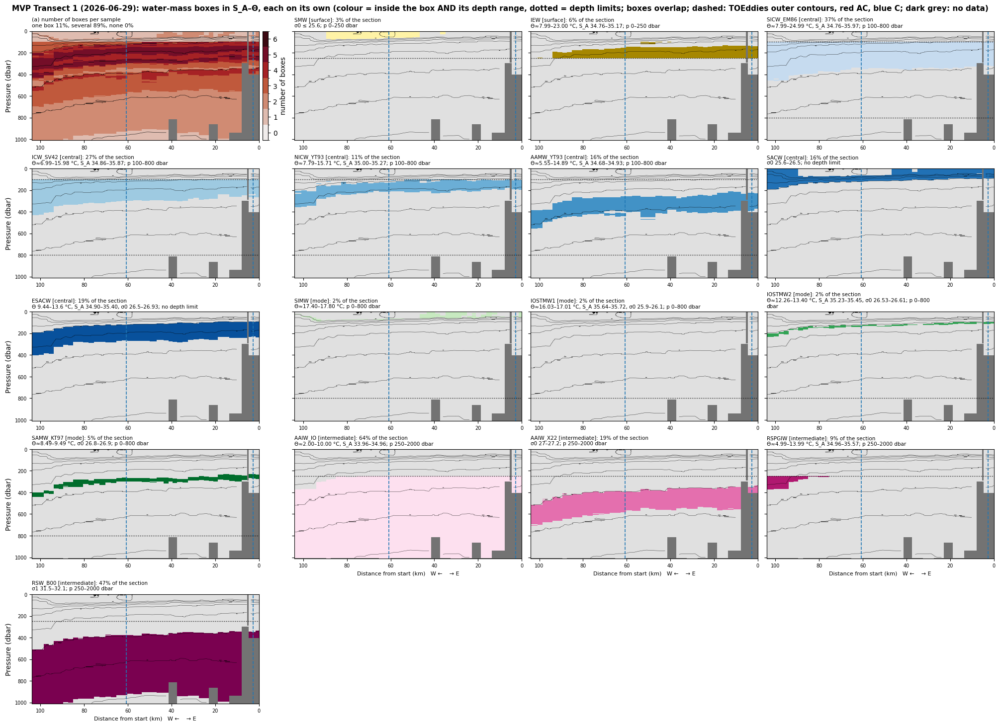

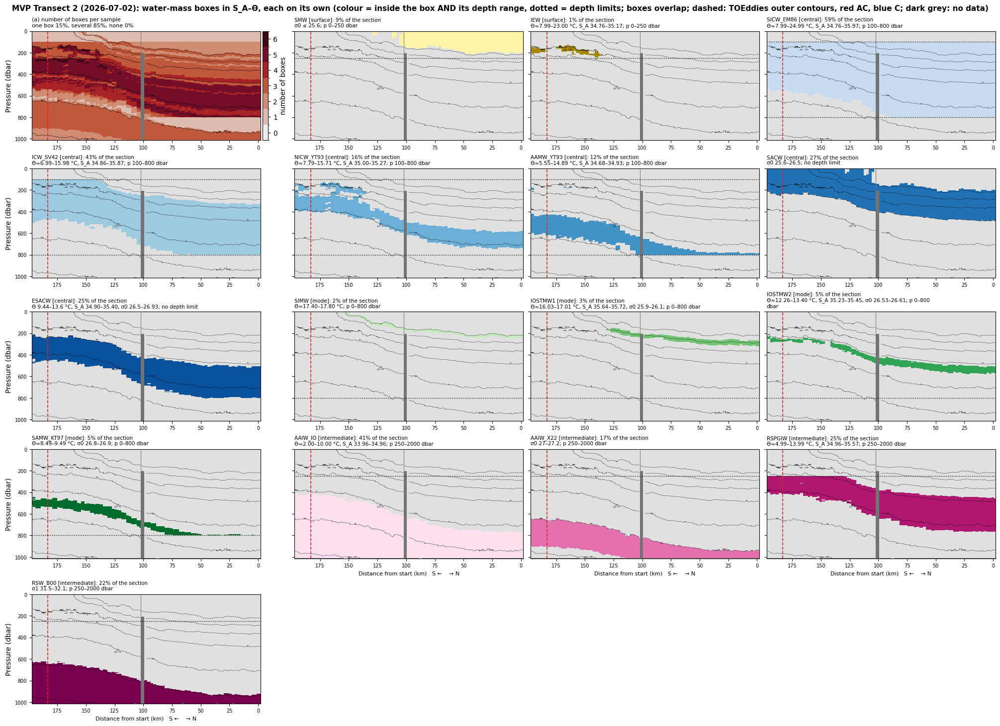

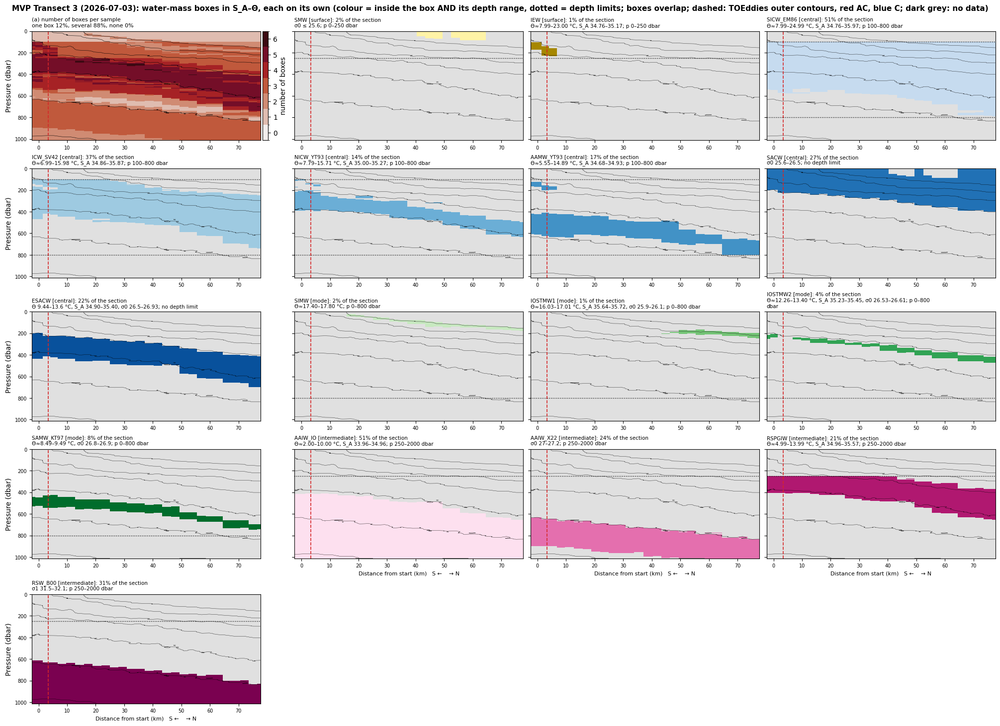

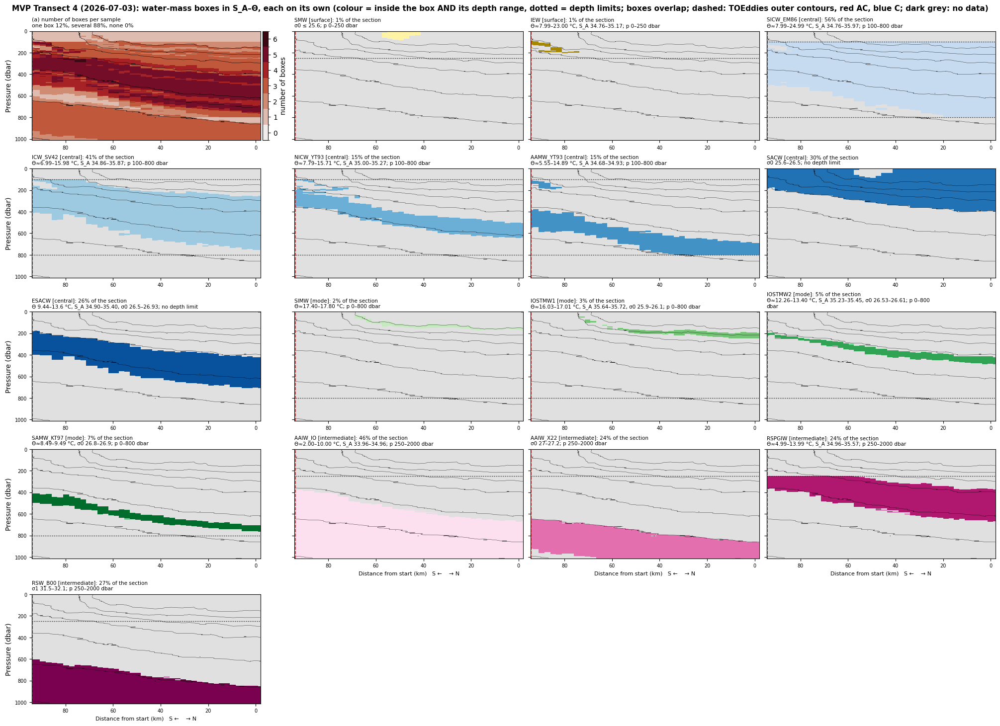

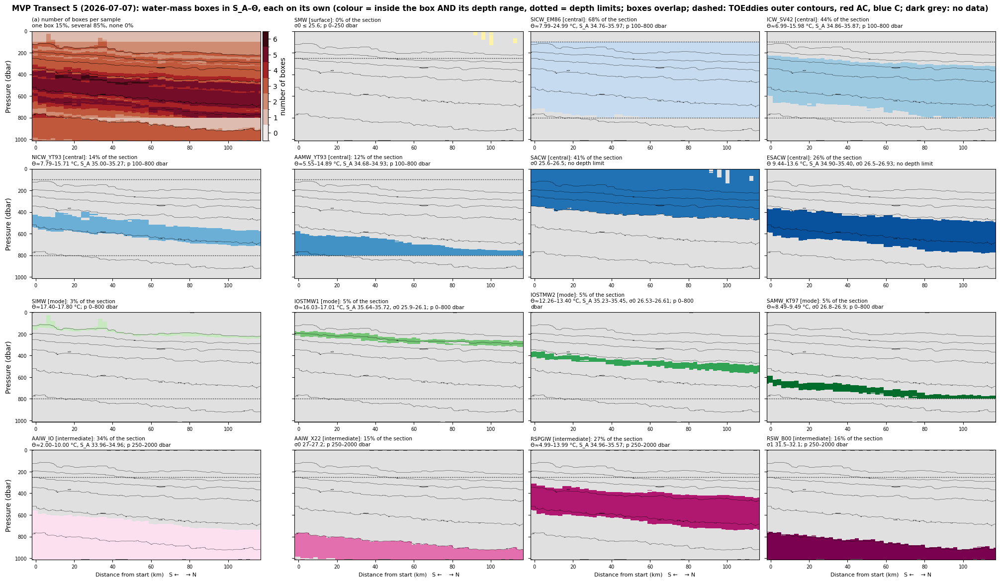

...

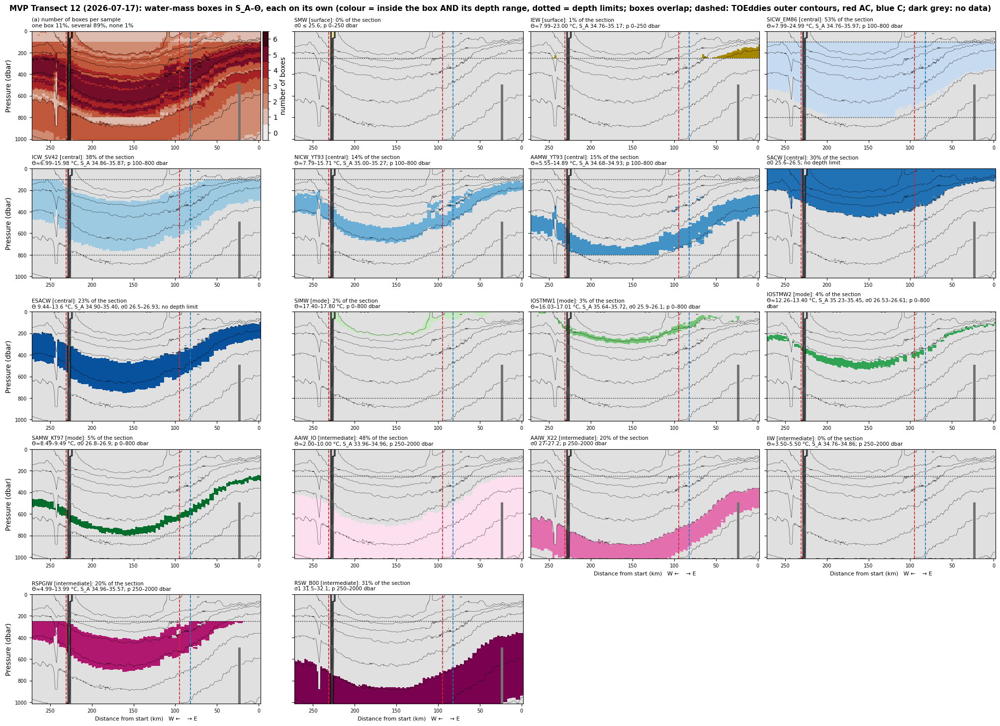

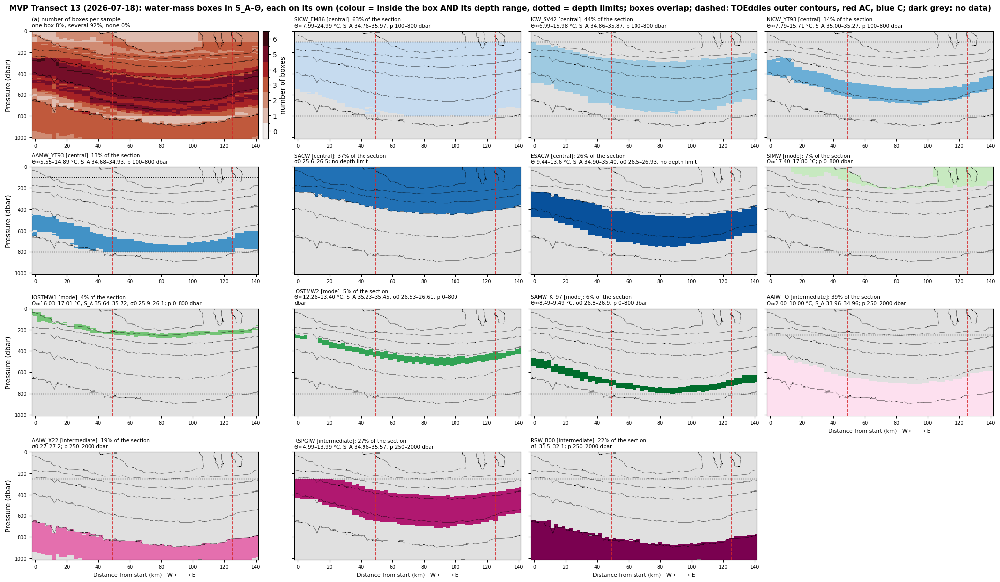

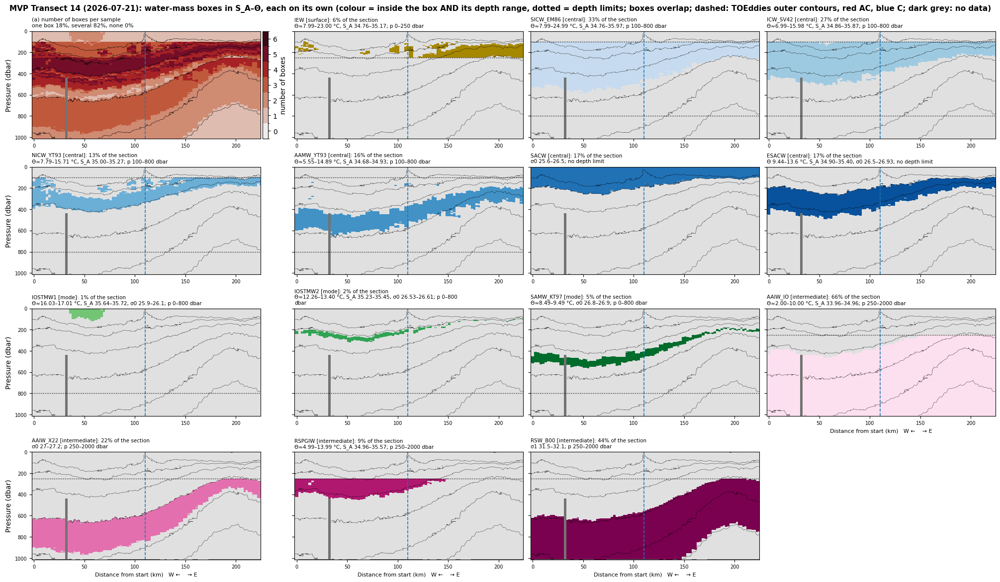

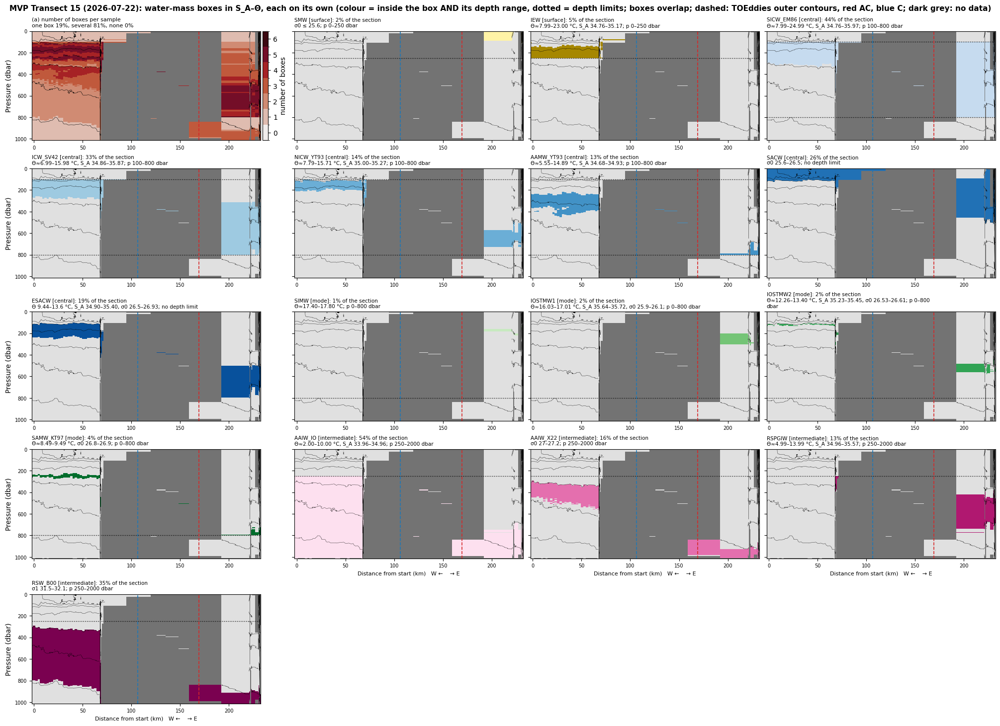

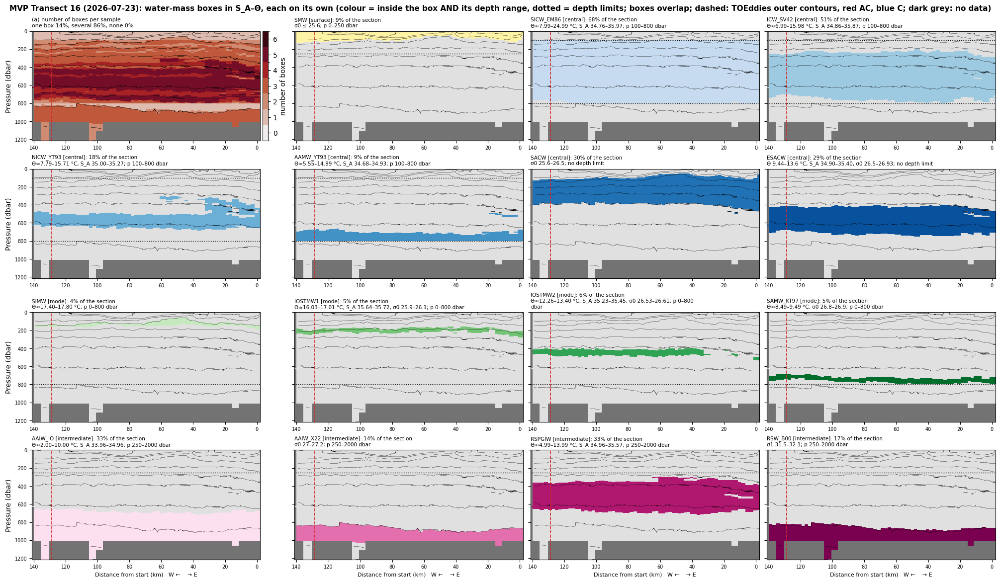

In [20]:
# ---------------- sections: colour = the combination of water masses of each sample ----------------
# No box has priority: a sample in several boxes gets the colour of that combination (and is hatched).
# The same combination has the same colour on every transect. Combinations below OTHER_MIN_PCT of all
# classified samples (all transects together) are grouped as "other combinations" (dark grey).
OTHER_MIN_PCT = 0.3
HATCH_OVERLAPS = False         # True: hatch samples in more than one box (almost all of them here)
PMAX = None                    # e.g. 1000 (dbar); None = deepest MVP bin of each transect

# colour-blind-safe qualitative colours: Paul Tol "muted" + "light", then Okabe-Ito
PALETTE = ["#332288", "#88CCEE", "#44AA99", "#117733", "#999933", "#DDCC77", "#CC6677", "#882255", "#AA4499",
           "#77AADD", "#EE8866", "#EEDD88", "#FFAABB", "#99DDFF", "#44BB99", "#BBCC33", "#AAAA00",
           "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]
OTHER_COLOR, NOBOX_COLOR, NODATA_COLOR = "0.35", "white", "0.85"

counts, sig_sum = Counter(), Counter()
for r in wm_runs:
    m = r["valid"] & (r["n_match"] > 0)
    c = r["wm_code"][m]
    counts.update(c.tolist())
    for cc, s in pd.Series(gsw.sigma0(r["sec"]["SA"][m], r["sec"]["CT"][m])).groupby(c).sum().items():
        sig_sum[cc] += s
total = sum(counts.values())
by_share = [c for c, k in counts.most_common() if 100 * k / total >= OTHER_MIN_PCT][:len(PALETTE)]
COMBO_COLOR = {c: PALETTE[k] for k, c in enumerate(by_share)}      # most common -> first colours
COMBO_ORDER = sorted(by_share, key=lambda c: sig_sum[c] / counts[c])  # light (bottom of bar) -> dense
n_other = total - sum(counts[c] for c in by_share)
print(f"{len(by_share)} combinations get their own colour; {len(counts) - len(by_share)} rarer ones "
      f"({100 * n_other / total:.1f}% of the classified samples) are drawn as 'other combinations'")


def combo_label(c, width=34):
    ids = combo_ids(c)
    if len(ids) == 1:
        b = WM_BY_ID[ids[0]]
        return ids[0] + "\n" + "\n".join(textwrap.wrap(f"({box_text(b)})", width))
    return "\n".join(textwrap.wrap(" + ".join(ids), width, break_on_hyphens=False)) + "  [overlap]"


def plot_wm_section(r, pmax=PMAX, savepath=None):
    sec = r["sec"]
    o = np.argsort(sec["x"])                      # casts in along-track order (pcolormesh needs monotonic x)
    xkm, p = sec["x"][o] / 1e3, sec["p"]
    v, code, nmatch, sig0 = r["valid"][:, o], r["wm_code"][:, o], r["n_match"][:, o], sec["sig0"][:, o]
    present = [c for c in COMBO_ORDER if np.any(v & (code == c))]
    has_other = np.any(v & (nmatch > 0) & ~np.isin(code, present))
    has_none = np.any(v & (nmatch == 0))
    cats = ([(NOBOX_COLOR, "no box")] if has_none else []) \
        + ([(OTHER_COLOR, "other combinations\n(rare, see printout)")] if has_other else []) \
        + [(COMBO_COLOR[c], combo_label(c)) for c in present]
    idx = np.full(v.shape, np.nan)
    k = 0
    if has_none:
        idx[v & (nmatch == 0)] = k; k += 1
    if has_other:
        idx[v & (nmatch > 0) & ~np.isin(code, present)] = k; k += 1
    for c in present:
        idx[v & (code == c)] = k; k += 1
    cmap = ListedColormap([c for c, _ in cats])
    norm = BoundaryNorm(np.arange(-0.5, len(cats)), cmap.N)

    fig, ax = plt.subplots(figsize=(15, max(4.8, 0.42 * len(cats) + 1.5)), constrained_layout=True)
    ax.set_facecolor(NODATA_COLOR)
    pc = ax.pcolormesh(xkm, p, idx, cmap=cmap, norm=norm, shading="nearest", rasterized=True)
    if HATCH_OVERLAPS and np.any(v & (nmatch > 1)):
        with plt.rc_context({"hatch.linewidth": 0.3, "hatch.color": "0.25"}):
            ax.contourf(xkm, p, (v & (nmatch > 1)).astype(float), levels=[0.5, 1.5],
                        colors="none", hatches=["////"])
    sig_levels = np.arange(np.floor(np.nanmin(sig0) * 4) / 4, np.nanmax(sig0), 0.25)
    cs = ax.contour(xkm, p, sig0, levels=sig_levels, colors="k", linewidths=0.5)
    ax.clabel(cs, cs.levels[::2], fontsize=7, fmt="%.2f")
    to_sn = make_to_sn(sec)
    for e in r["edds"]:
        for xv in crossings_on_line(e["outer"], to_sn):
            ax.axvline(xv, color="tab:blue" if e["cyc"] else "tab:red", ls="--", lw=1.4)
    ax.set_ylim(pmax or np.nanmax(p), 0)
    ax.set_xlim(np.nanmin(xkm), np.nanmax(xkm))
    if r["wm_flip"]:
        ax.invert_xaxis()
    ax.set_ylabel("Pressure (dbar)")
    ax.set_xlabel(f"Distance from start of transect (km)        {r['wm_dir']}")
    ax.set_title(f"MVP {r['transect']} ({r['date']}): water masses in S_A–Θ  (dashed: TOEddies outer contours, "
                 f"red AC, blue C; "
                 f"most samples are in several boxes, see the per-box figure; grey: no data)", loc="left", fontsize=10)
    cb = fig.colorbar(pc, ax=ax, ticks=range(len(cats)), pad=0.01, aspect=max(20, 3 * len(cats)))
    cb.ax.set_yticklabels([lab for _, lab in cats], fontsize=7)
    if savepath:
        fig.savefig(savepath, dpi=300, bbox_inches="tight")
    return fig, ax


GROUP_COLORS = {"surface": "#E69F00", "central": "#0072B2", "mode": "#009E73",
                "intermediate": "#CC79A7", "deep": "#000000"}          # Okabe-Ito


def decorate_wm(ax, r, xkm, sig0, sig_levels, lw=0.5, label=True):
    cs = ax.contour(xkm, r["sec"]["p"], sig0, levels=sig_levels, colors="k", linewidths=lw)
    if label:
        ax.clabel(cs, cs.levels[::2], fontsize=6, fmt="%.2f")
    to_sn = make_to_sn(r["sec"])
    for e in r["edds"]:
        for xv in crossings_on_line(e["outer"], to_sn):
            ax.axvline(xv, color="tab:blue" if e["cyc"] else "tab:red", ls="--", lw=1.2)


def plot_wm_box_panels(r, pmax=PMAX, ncol=4, savepath=None, transect_1=False):
    """Main figure: (a) number of boxes each sample is in, then one panel per box that holds data
    (colour = inside the box, light grey = data outside the box). No priority between boxes."""
    sec = r["sec"]
    o = np.argsort(sec["x"])
    xkm, p = sec["x"][o] / 1e3, sec["p"]
    v, nmatch, sig0 = r["valid"][:, o], r["n_match"][:, o], sec["sig0"][:, o]
    sig_levels = np.arange(np.floor(np.nanmin(sig0) * 4) / 4, np.nanmax(sig0), 0.25)
    boxes = [b for b in WM_BOXES if np.any(r["wm_masks"][b["id"]] & r["valid"])]   # only boxes present within their depth range
    nrow = int(np.ceil((len(boxes) + 1) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(5.0 * ncol, 2.9 * nrow), sharex=True, sharey=True,
                            constrained_layout=True)
    axs = axs.ravel()
    nmax = max(1, int(np.nanmax(np.where(v, nmatch, 0))))
    pc = axs[0].pcolormesh(xkm, p, np.where(v, nmatch, np.nan), cmap=cmocean.cm.amp,
                           norm=BoundaryNorm(np.arange(-0.5, nmax + 1), 256), shading="nearest", rasterized=True)
    fig.colorbar(pc, ax=axs[0], ticks=range(nmax + 1), pad=0.01, label="number of boxes")
    decorate_wm(axs[0], r, xkm, sig0, sig_levels, lw=0.4, label=False)
    axs[0].set_title(f"(a) number of boxes per sample\none box {100 * np.mean(nmatch[v] == 1):.0f}%, "
                     f"several {100 * np.mean(nmatch[v] > 1):.0f}%, none {100 * np.mean(nmatch[v] == 0):.0f}%",
                     loc="left", fontsize=8)
    for ax, b in zip(axs[1:], boxes):
        m = r["wm_masks"][b["id"]][:, o]
        ax.pcolormesh(xkm, p, np.where(v, 0.0, np.nan), cmap=ListedColormap(["0.88"]), shading="nearest",
                      rasterized=True)
        col = b["color"]                     # fixed colour per box (water_masses.WM_COLORS)
        ax.pcolormesh(xkm, p, np.where(m & v, 1.0, np.nan), cmap=ListedColormap([col]),       # within depth range only
                      vmin=0, vmax=1, shading="nearest", rasterized=True)
        for lim in (b["p"] or ()):
            if lim:
                ax.axhline(lim, color="k", ls=":", lw=1.0)
        decorate_wm(ax, r, xkm, sig0, sig_levels, lw=0.3, label=False)
        ax.set_title(f"{b['id']} [{b['group']}]: {100 * np.sum(m & v) / v.sum():.0f}% of the section\n"
                     + "\n".join(textwrap.wrap(box_text(b) + "; " + depth_text(b), 62)), loc="left", fontsize=7.5)
    for ax in axs[len(boxes) + 1:]:
        ax.set_visible(False)
    for ax in axs[:len(boxes) + 1]:
        ax.set_facecolor("0.45")                 # no data (light grey = data outside the box)
        ax.tick_params(labelbottom=True, labelsize=7)
    axs[0].set_ylim(pmax or np.nanmax(p), 0)
    axs[0].set_xlim(np.nanmin(xkm), np.nanmax(xkm))
    if r["wm_flip"]:
        axs[0].invert_xaxis()
    if transect_1:
        for ax in axs:
            ax.set_xlim(104, 0)
    for ax in axs[::ncol]:
        ax.set_ylabel("Pressure (dbar)")
    for ax in axs[max(0, len(boxes) + 1 - ncol):len(boxes) + 1]:
        ax.set_xlabel(f"Distance from start (km)   {r['wm_dir']}", fontsize=8)
    fig.suptitle(f"MVP {r['transect']} ({r['date']}): water-mass boxes in S_A–Θ, each on its own "
                 "(colour = inside the box AND its depth range, dotted = depth limits; "
                 "boxes overlap; dashed: TOEddies outer contours, red AC, blue C; dark grey: no data)", fontsize=11, fontweight="bold")
    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight")
    return fig, axs


SHOW_COMBINATIONS = False       # also draw the single-panel section coloured by combination of boxes
for r in wm_runs:
    out = BASE / "figures/mvp" / r["transect"]
    os.makedirs(out, exist_ok=True)
    stem = r["transect"].replace(" ", "_")
    plot_wm_box_panels(r, savepath=out / f"{stem}_water_mass_boxes_SA_CT.png", transect_1 = r['transect'] == "Transect 1")
    plt.show()
    if SHOW_COMBINATIONS:
        fig, ax = plot_wm_section(r, savepath=out / f"{stem}_water_masses_SA_CT.png")
        plt.show()

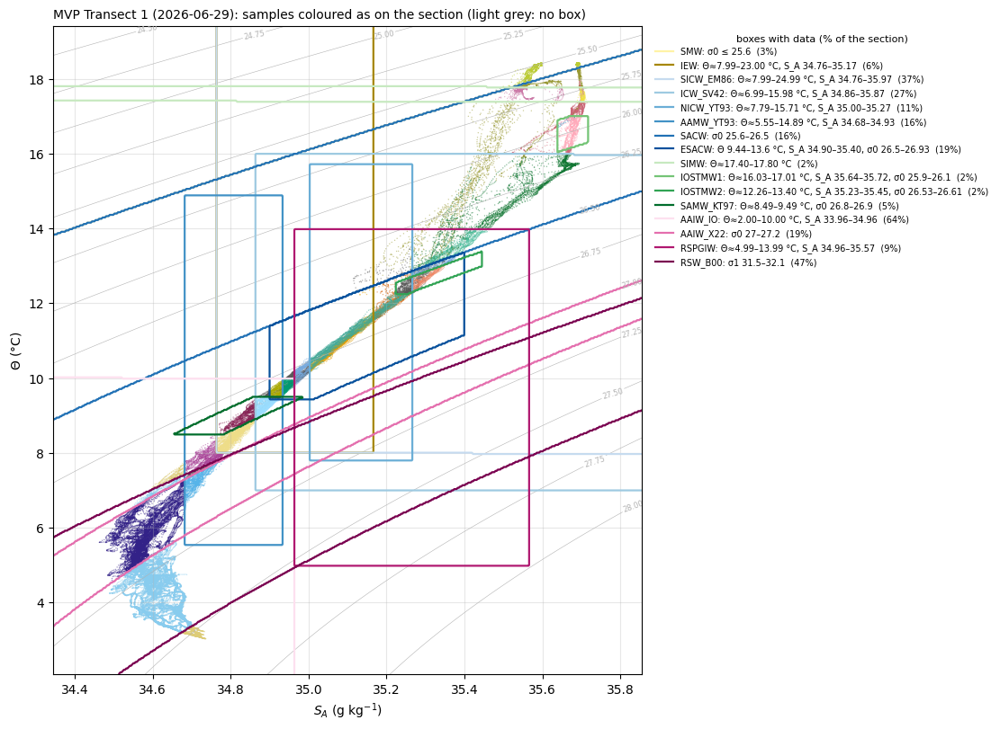

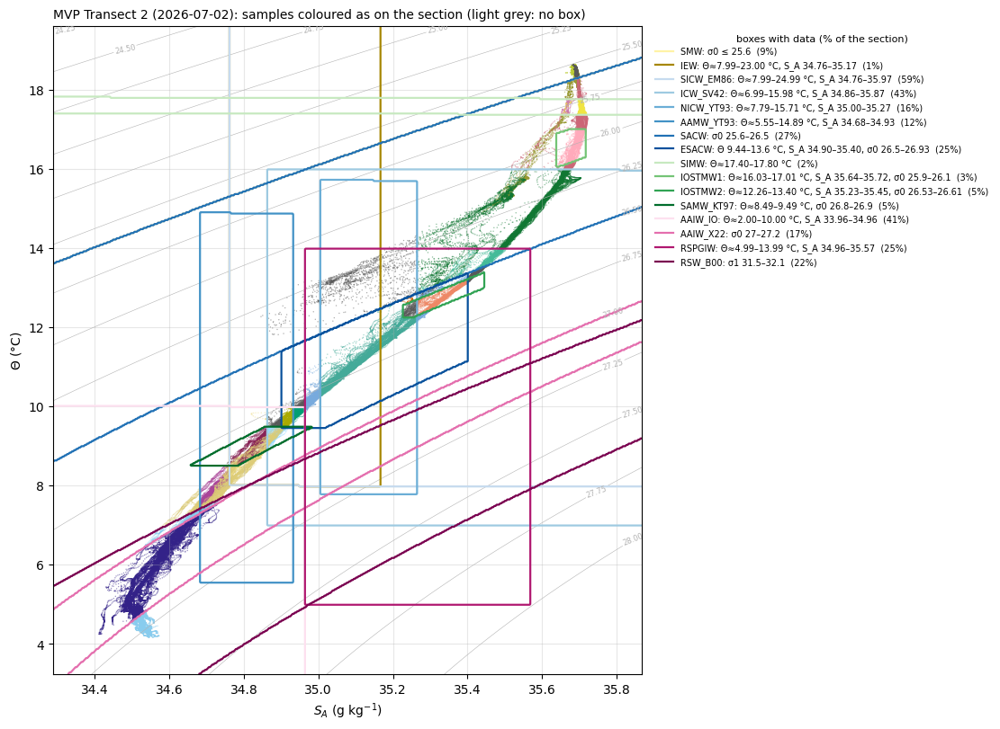

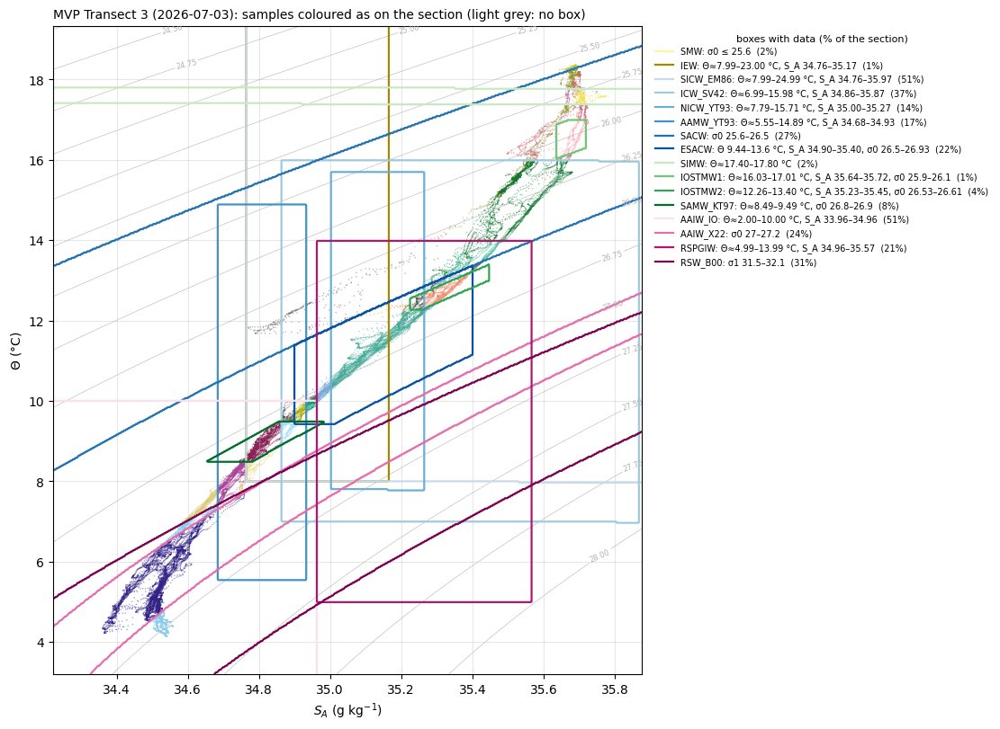

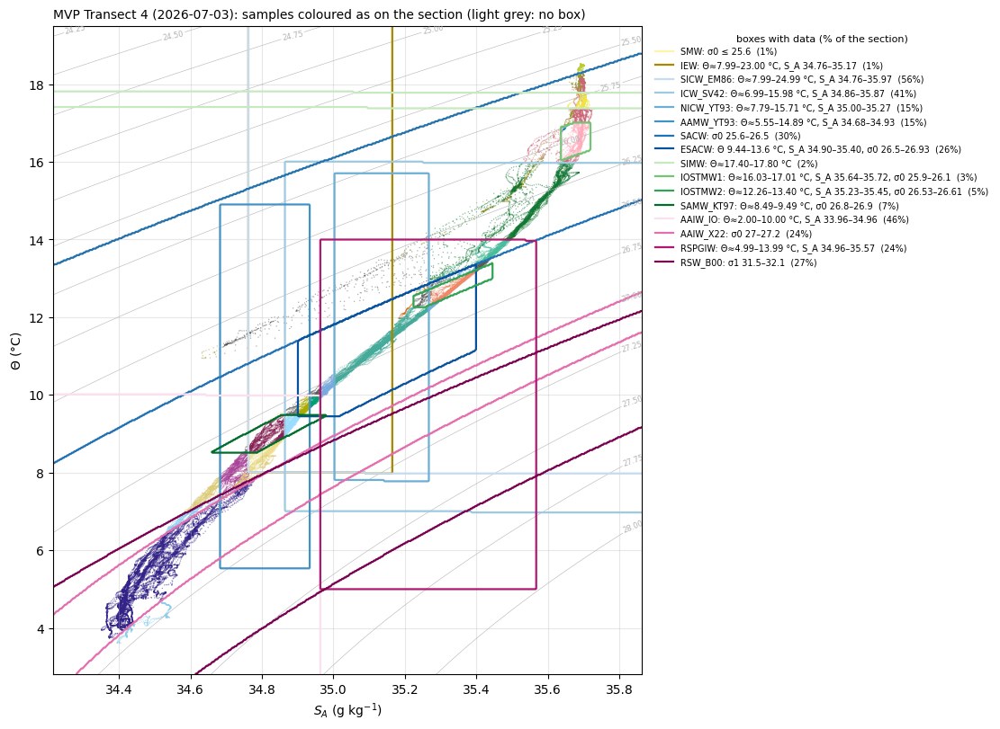

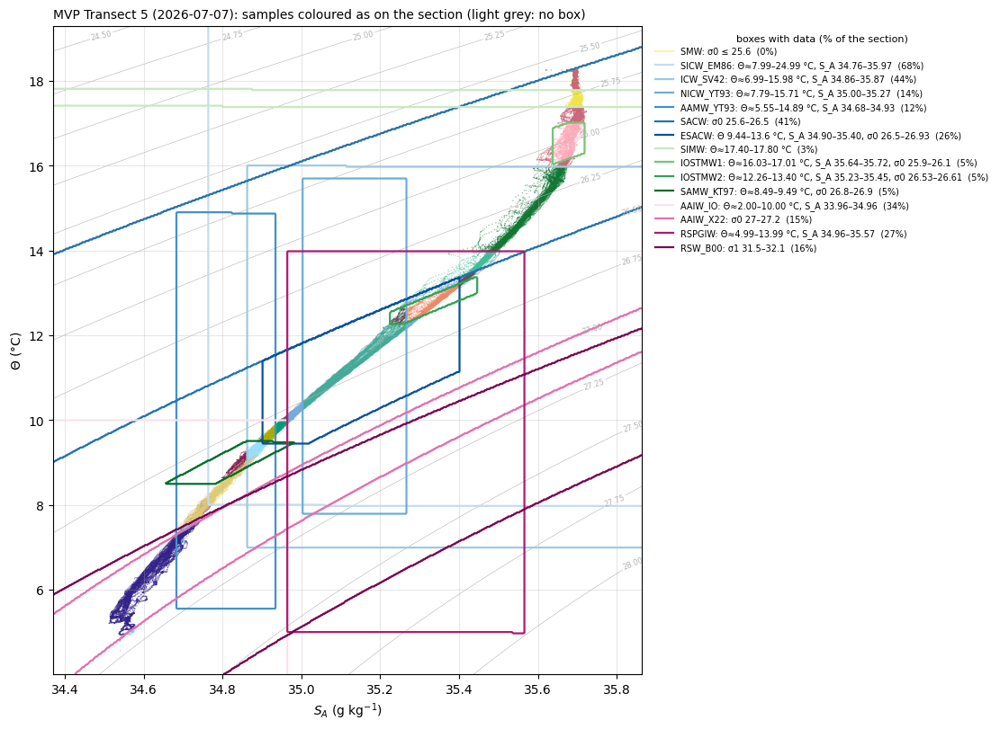

...

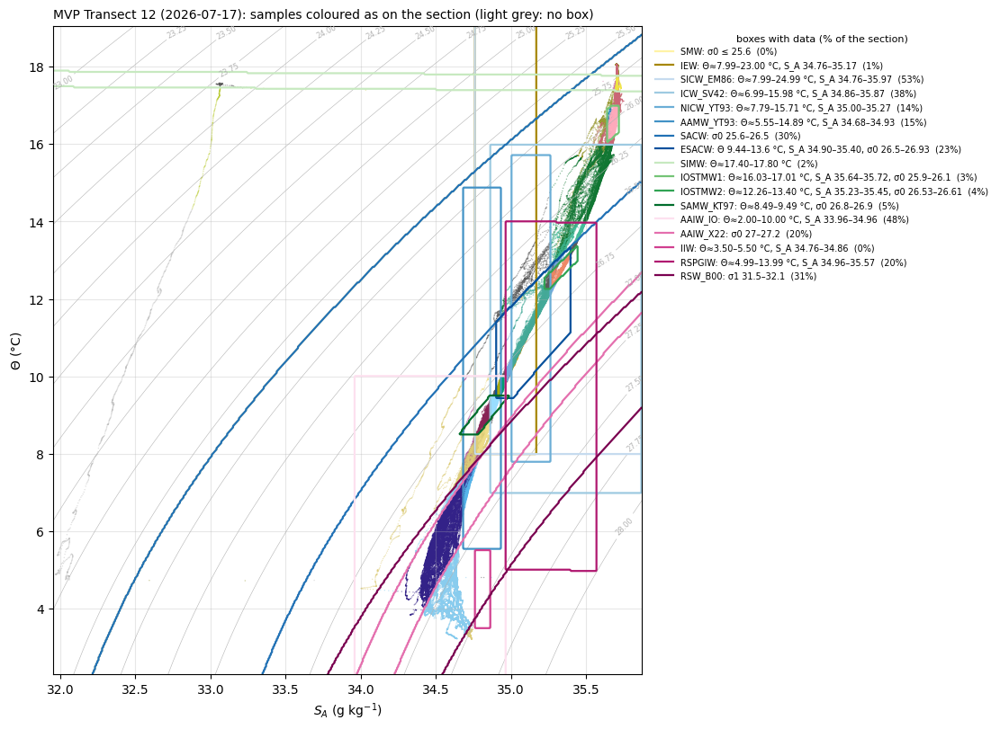

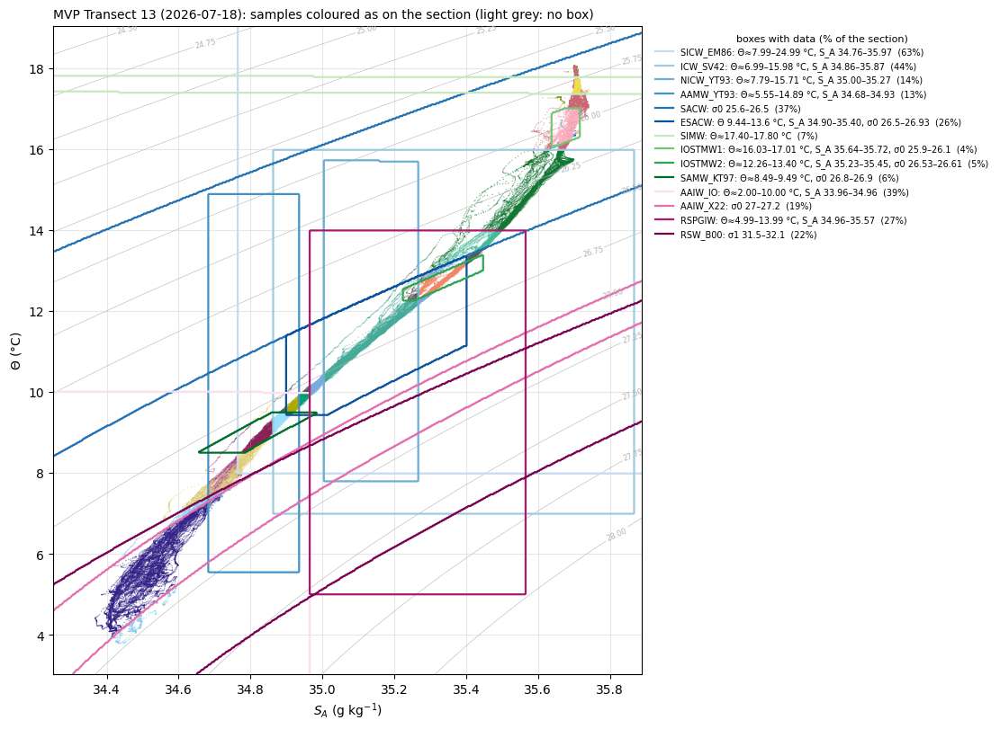

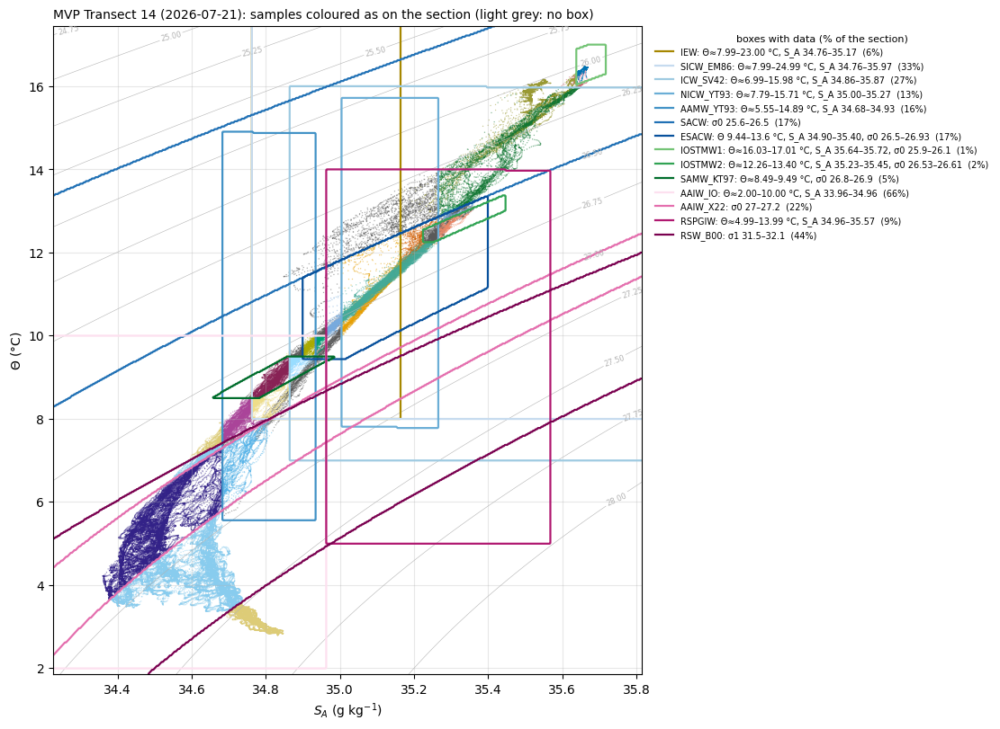

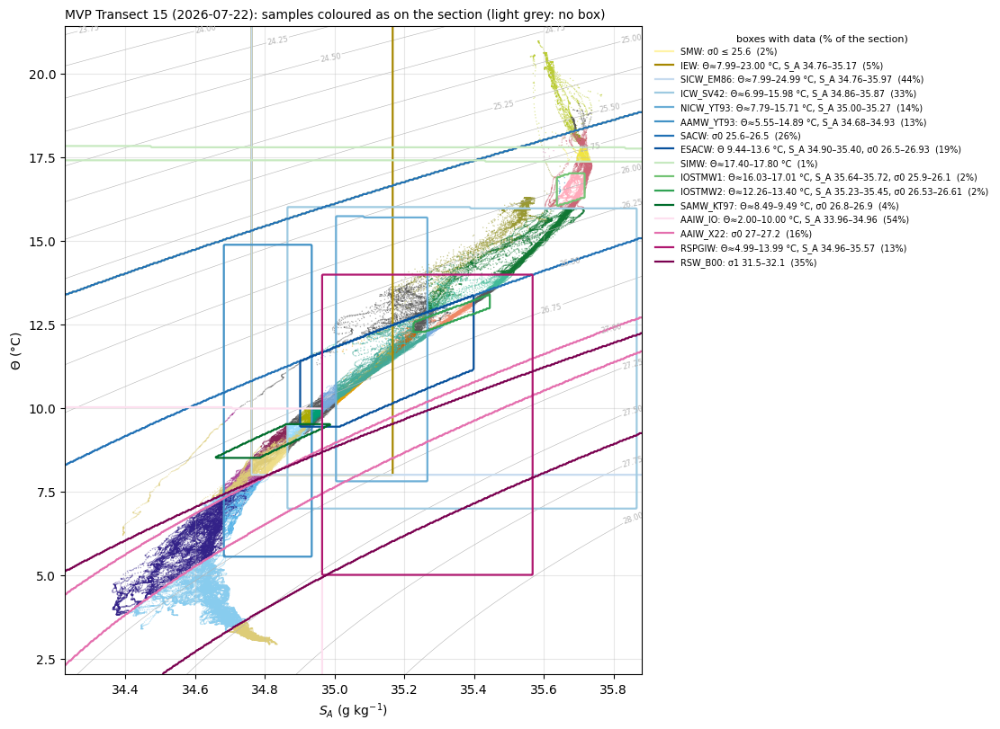

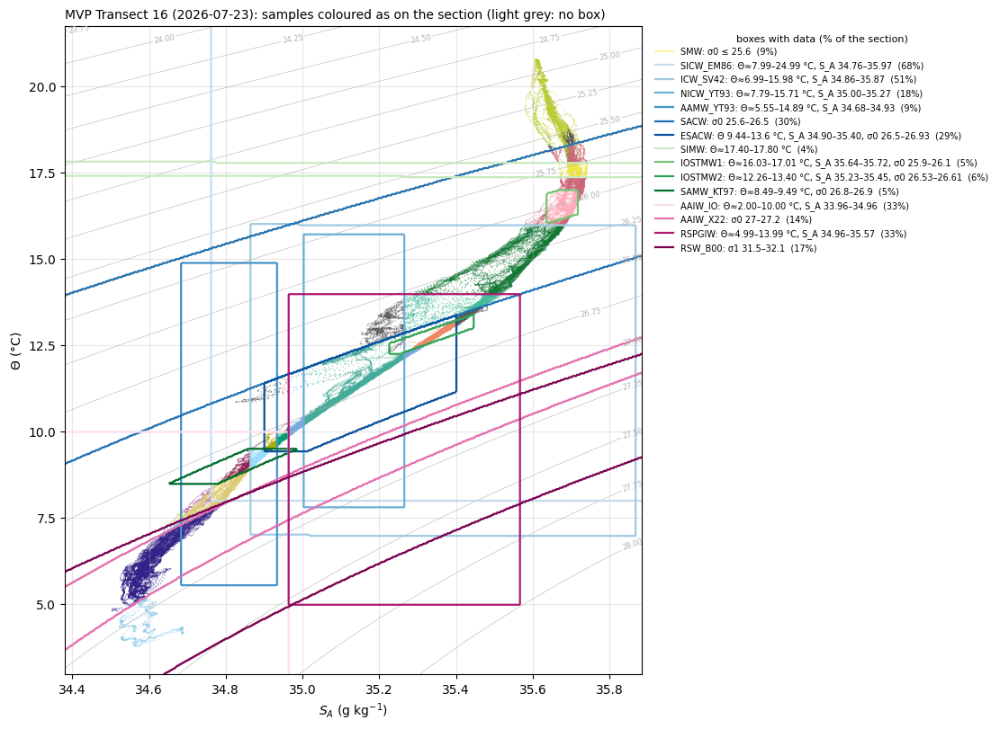

In [21]:
# ---------------- S_A - Theta diagram of each transect, with the boxes drawn in S_A - Theta ----------------
# Each box is drawn as the outline of box_mask on a fine S_A - Theta grid, so a theta limit appears as
# the curve Theta = CT_from_pt(S_A, theta) and a sigma limit as an isopycnal: exactly what is tested.
# Only boxes that contain at least one sample of the transect are drawn.
SHOW_TS = True
BOX_LS = ["-", "--", ":", "-."]


def plot_wm_ts(r, savepath=None):
    sec, v, code = r["sec"], r["valid"], r["wm_code"]
    SA, CT = sec["SA"][v], sec["CT"][v]
    cols = np.array([COMBO_COLOR.get(c, OTHER_COLOR) if c else "0.75" for c in code[v].tolist()], dtype=object)
    fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
    ax.scatter(SA, CT, s=1, c=list(cols), alpha=0.5, lw=0, rasterized=True)
    ax.set_xlim(np.nanpercentile(SA, 0.2) - 0.15, np.nanpercentile(SA, 99.8) + 0.15)
    ax.set_ylim(np.nanpercentile(CT, 0.2) - 1.0, np.nanpercentile(CT, 99.8) + 1.0)
    SAg, CTg = np.meshgrid(np.linspace(*ax.get_xlim(), 500), np.linspace(*ax.get_ylim(), 500))
    cs = ax.contour(SAg, CTg, gsw.sigma0(SAg, CTg), levels=np.arange(23, 28.01, 0.25), colors="0.7", linewidths=0.4)
    ax.clabel(cs, fmt="%.2f", fontsize=6)
    handles = []
    shown = [b for b in WM_BOXES if r["wm_masks"][b["id"]][v].any()]
    for k, b in enumerate(shown):
        col, ls = b["color"], "-"            # fixed colour per box (water_masses.WM_COLORS)
        mg = box_mask(b, SAg, CTg).astype(float)
        if mg.any():
            ax.contour(SAg, CTg, mg, levels=[0.5], colors=[col], linewidths=1.6, linestyles=ls)
        handles.append(mlines.Line2D([], [], color=col, ls=ls, lw=1.6,
                                     label=f"{b['id']}: {box_text(b)}  ({100 * r['wm_masks'][b['id']][v].mean():.0f}%)"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=7, frameon=False,
              title="boxes with data (% of the section)", title_fontsize=8)
    ax.set_xlabel(r"$S_A$ (g kg$^{-1}$)"); ax.set_ylabel(r"$\Theta$ (°C)")
    ax.set_title(f"MVP {r['transect']} ({r['date']}): samples coloured as on the section "
                 "(light grey: no box)", loc="left", fontsize=10)
    ax.grid(alpha=0.3)
    if savepath:
        fig.savefig(savepath, dpi=300, bbox_inches="tight")
    return fig, ax


if SHOW_TS:
    for r in wm_runs:
        plot_wm_ts(r, savepath=BASE / "figures/mvp" / r["transect"] /
                   f"{r['transect'].replace(' ', '_')}_water_masses_TS_SA_CT.png")
        plt.show()

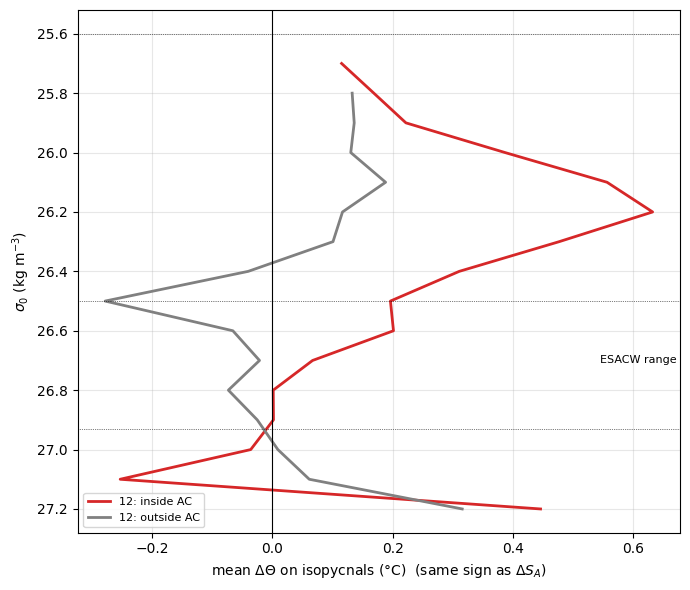

In [22]:
# ---------------- spiciness on isopycnals: is the core water "Indian" (warmer AND saltier)? ----------------
# Along an isopycnal, Theta and S_A anomalies have the same sign (density-compensated):
# positive = warmer and saltier = more Indian-Ocean-like; negative = colder and fresher.
rho_levels = np.round(np.arange(25.6, 27.21, 0.1), 2)
fig, ax = plt.subplots(figsize=(7, 6))
for r, ls in zip(runs, ["-", "--"]):
    sec = r["sec"]
    for m, col, lab in [(r["in_ac"], "tab:red", "inside AC"), (~r["in_ac"], "0.5", "outside AC")]:
        if not m.any():
            continue
        dct = np.array([interp_on_rho(sec["sig0"][:, i], r["anoms"]["CT"][:, i], rho_levels)
                        for i in np.flatnonzero(m)])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            ax.plot(np.nanmean(dct, axis=0), rho_levels, ls, color=col, lw=2,
                    label=f"{r['transect'].split()[-1]}: {lab}")
ax.axvline(0, color="k", lw=0.8)
for y in [25.6, 26.5, 26.93]:
    ax.axhline(y, color="k", lw=0.5, ls=":")
ax.text(ax.get_xlim()[1], 26.7, "ESACW range ", ha="right", va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlabel(r"mean $\Delta\Theta$ on isopycnals (°C)  (same sign as $\Delta S_A$)")
ax.set_ylabel(r"$\sigma_0$ (kg m$^{-3}$)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Origin of the water masses
Approximate origin / formation box of each water mass, from the "Origin and formation regions" table of `writing/Agulhas_Retroflection_water_masses_WHIRLS_FINAL_origins.docx` (schematic only). Filled + solid = found in the MVP sections (`pres`, from the classification cell), dotted = not found. Saved to `figures/mvp/water_mass_origins_map.png`.

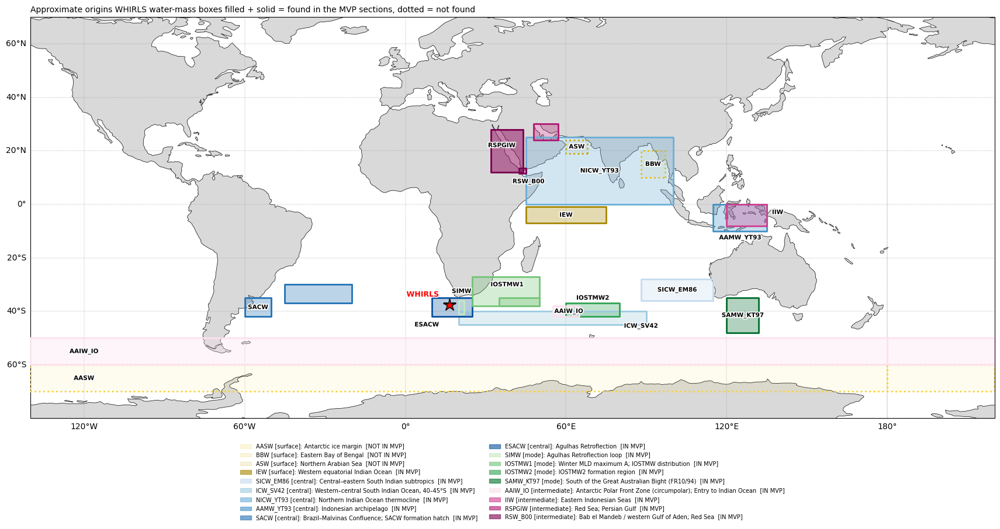

In [23]:
# ---------------- where each water mass comes from: origin / formation boxes on a map ----------------
# Boxes from the "Origin and formation regions" table of
# writing/Agulhas_Retroflection_water_masses_WHIRLS_FINAL_origins.docx (approximate, schematic only).
# Each entry: (lon_min, lon_max, lat_min, lat_max, region, basis); lon in [-180, 180], "all longitudes" = -180..180.
# Filled = the water mass is found in the WHIRLS MVP data (column "In WHIRLS data" of `pres`), dotted = not found.
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import shapely.geometry as sgeom
import matplotlib.patheffects as pe
import matplotlib.patches as mpatches

ALL = (-180, 180)
WM_ORIGINS = {
    "SMW":       [],   # no region given (excess evaporation in tropical regions)
    "AASW":      [(*ALL, -70, -60, "Antarctic ice margin", "Place name")],
    "BBW":       [(88, 97, 10, 20, "Eastern Bay of Bengal", "Map (Fig. 1)")],
    "ASW":       [(60, 68, 19, 24, "Northern Arabian Sea", "Map (Fig. 1)")],
    "IEW":       [(45, 75, -7, -1, "Western equatorial Indian Ocean", "Map (Fig. 1)")],
    "IUW":       [(118, 132, -8, 0, "Indonesian Seas", "Map (Fig. 1)")],
    "SICW_EM86": [(88, 115, -36, -28, "Central–eastern South Indian subtropics", "Map (Fig. 1)")],
    "ICW_SV42":  [(20, 90, -45, -40, "Western–central South Indian Ocean, 40–45°S", "Latitude stated; longitude from place name")],
    "NICW_YT93": [(45, 100, 0, 25, "Northern Indian Ocean thermocline", "Place name")],
    "AAMW_YT93": [(115, 135, -10, 0, "Indonesian archipelago", "Place name")],
    "SACW":      [(-60, -50, -42, -35, "Brazil–Malvinas Confluence", "Place name"),
                  (-45, -20, -37, -30, "SACW formation hatch", "Map (Fig. 1)")],
    "ESACW":     [(10, 25, -42, -35, "Agulhas Retroflection", "Place name")],
    "SIMW":      [(20, 22, -41, -36, "Agulhas Retroflection loop", "Longitude stated; latitude from place name")],
    "IOSTMW1":   [(35, 50, -38, -35, "Winter MLD maximum A", "Stated"),
                  (25, 50, -38, -27, "IOSTMW distribution", "Stated")],
    "IOSTMW2":   [(60, 80, -42, -37, "IOSTMW2 formation region", "Stated")],
    "SAMW_KT97": [(120, 132, -48, -35, "South of the Great Australian Bight (FR10/94)", "Stated (section limits)")],
    "AAIW_IO":   [(*ALL, -60, -50, "Antarctic Polar Front Zone (circumpolar)", "Map (Fig. 2)"),
                  (55, 65, -42, -38, "Entry to Indian Ocean", "Stated")],
    "AAIW_X22":  [],   # no region given (see AAIW_IO)
    "IIW":       [(120, 135, -8, 0, "Eastern Indonesian Seas", "Map (Fig. 2)")],
    "RSPGIW":    [(32, 44, 12, 28, "Red Sea", "Map (Fig. 2)"), (48, 57, 24, 30, "Persian Gulf", "Map (Fig. 2)")],
    "RSW_B00":   [(42.5, 45, 11.5, 13.5, "Bab el Mandeb / western Gulf of Aden", "Place name"),
                  (32, 44, 12, 28, "Red Sea", "Place name")],
    "NADW":      [(-60, -10, 50, 65, "Subpolar North Atlantic", "Map (Fig. 3)")],
    "CDW":       [(*ALL, -65, -45, "Antarctic Circumpolar Current band", "Place name")],
    "AABW":      [(-60, 0, -78, -60, "Weddell Sea", "Place name; map (Fig. 3)")],
}
# where to write each label (lon, lat); default = centre of the first box. Set by hand where boxes are crowded.
LABEL_AT = {"AASW": (-120, -65), "AAIW_IO": (-120, -55), "CDW": (-160, -47.5), "IUW": (124, 2), "IIW": (139, -3),
            "AAMW_YT93": (125, -12.5), "RSPGIW": (36, 22), "RSW_B00": (46, 8.5), "ESACW": (8, -45),
            "SIMW": (21, -32.5), "IOSTMW1": (38, -30), "ICW_SV42": (88, -45.5), "IOSTMW2": (70, -35),
            "AAIW_IO@2": (61, -40)}
WHIRLS_LONLAT = (16.5, -37.5)
BAND_HATCH = {"AASW": "....", "AAIW_IO": "////", "CDW": "\\\\"}   # circumpolar bands: one hatch each
missing = [i for i in WM_IDS if i not in WM_ORIGINS]
if missing:
    print("no origin box defined for:", ", ".join(missing))

try:
    in_mvp = dict(pres["In WHIRLS data (MVP)"] == "yes")
except NameError:                                  # classification cell not run: no fill information
    in_mvp = {}

fig = plt.figure(figsize=(17, 11), constrained_layout=True)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree(central_longitude=40))
ax.set_extent([-180, 180, -80, 70], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="0.85", zorder=1)
ax.coastlines(resolution="110m", linewidth=0.5, zorder=2)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.3, color="0.6", linestyle="--")
gl.top_labels = gl.right_labels = False
halo = [pe.withStroke(linewidth=2.5, foreground="white")]
handles, no_region = [], []
for k, b in enumerate(WM_BOXES):
    i = b["id"]
    boxes = WM_ORIGINS.get(i, [])
    if not boxes:
        no_region.append(i)
        continue
    col = b["color"]                         # same colour as on every section (water_masses.WM_COLORS)
    found = in_mvp.get(i)
    for j, (x0, x1, y0, y1, region, basis) in enumerate(boxes):
        band = (x0, x1) == ALL
        geom = sgeom.box(x0, y0, x1, y1)
        ls = "-" if found else ":"
        # if band:      # circumpolar band: light hatch + its two latitude lines (no seam at the map edge)
        #     with plt.rc_context({"hatch.linewidth": 0.5}):
        #         ax.add_geometries([geom], crs=ccrs.PlateCarree(), facecolor="none", edgecolor=col, linewidth=0,
        #                           hatch=BAND_HATCH.get(i, ".."), alpha=0.5, zorder=3)
        #     for lat in (y0, y1):
        #         ax.plot([-180, 0, 180], [lat] * 3, color=col, lw=1.4, ls=ls, transform=ccrs.PlateCarree(), zorder=4)
        # else:
        ax.add_geometries([geom], crs=ccrs.PlateCarree(), facecolor=col, alpha=0.3 if found else 0.08,
                            edgecolor="none", zorder=3)
        ax.add_geometries([geom], crs=ccrs.PlateCarree(), facecolor="none", edgecolor=col,
                              linewidth=2.0, linestyle=ls, zorder=4)          # every box of a water mass looks the same
        key = i if j == 0 else f"{i}@{j + 1}"
        if j == 0 or key in LABEL_AT:
            lx, ly = LABEL_AT.get(key, ((x0 + x1) / 2, (y0 + y1) / 2))
            ax.text(lx, ly, i, transform=ccrs.PlateCarree(), fontsize=7.5, fontweight="bold", color="k",
                    ha="center", va="center", path_effects=halo, zorder=6)
    regions = "; ".join(f"{r}" for *_, r, bs in boxes)
    tag = "" if found is None else ("  [IN MVP]" if found else "  [NOT IN MVP]")
    handles.append(mpatches.Patch(facecolor=col, alpha=0.6 if found or found is None else 0.15, edgecolor=col,
                                  hatch=BAND_HATCH.get(i) if boxes[0][:2] == ALL else None,
                                  label=f"{i} [{b['group']}]: {regions}{tag}"))
ax.plot(*WHIRLS_LONLAT, marker="*", ms=16, mfc="red", mec="k", transform=ccrs.PlateCarree(), zorder=7)
ax.text(WHIRLS_LONLAT[0] - 4, WHIRLS_LONLAT[1] + 3, "WHIRLS", color="red", fontsize=9, fontweight="bold",
        transform=ccrs.PlateCarree(), ha="right", path_effects=halo, zorder=7)
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=2, fontsize=7, frameon=False)
# note = "No origin region given: " + ", ".join(no_region) if no_region else ""
ax.set_title("Approximate origins WHIRLS water-mass boxes "
             "filled + solid = found in the MVP sections, dotted = not found", fontsize=10, loc="left")
fig.savefig(BASE / "figures/mvp/water_mass_origins_map.png", dpi=250, bbox_inches="tight")
plt.show()